<a href="https://colab.research.google.com/github/haniyathul/TESIS-HANIY/blob/main/SIMULASI_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

VISUALISASI GRID10 MODERATE
Scenario : 18
Rows     : 1800
Rho data : [np.float64(0.5)]

✅ rho akan dibaca dari data, bukan ditentukan manual.


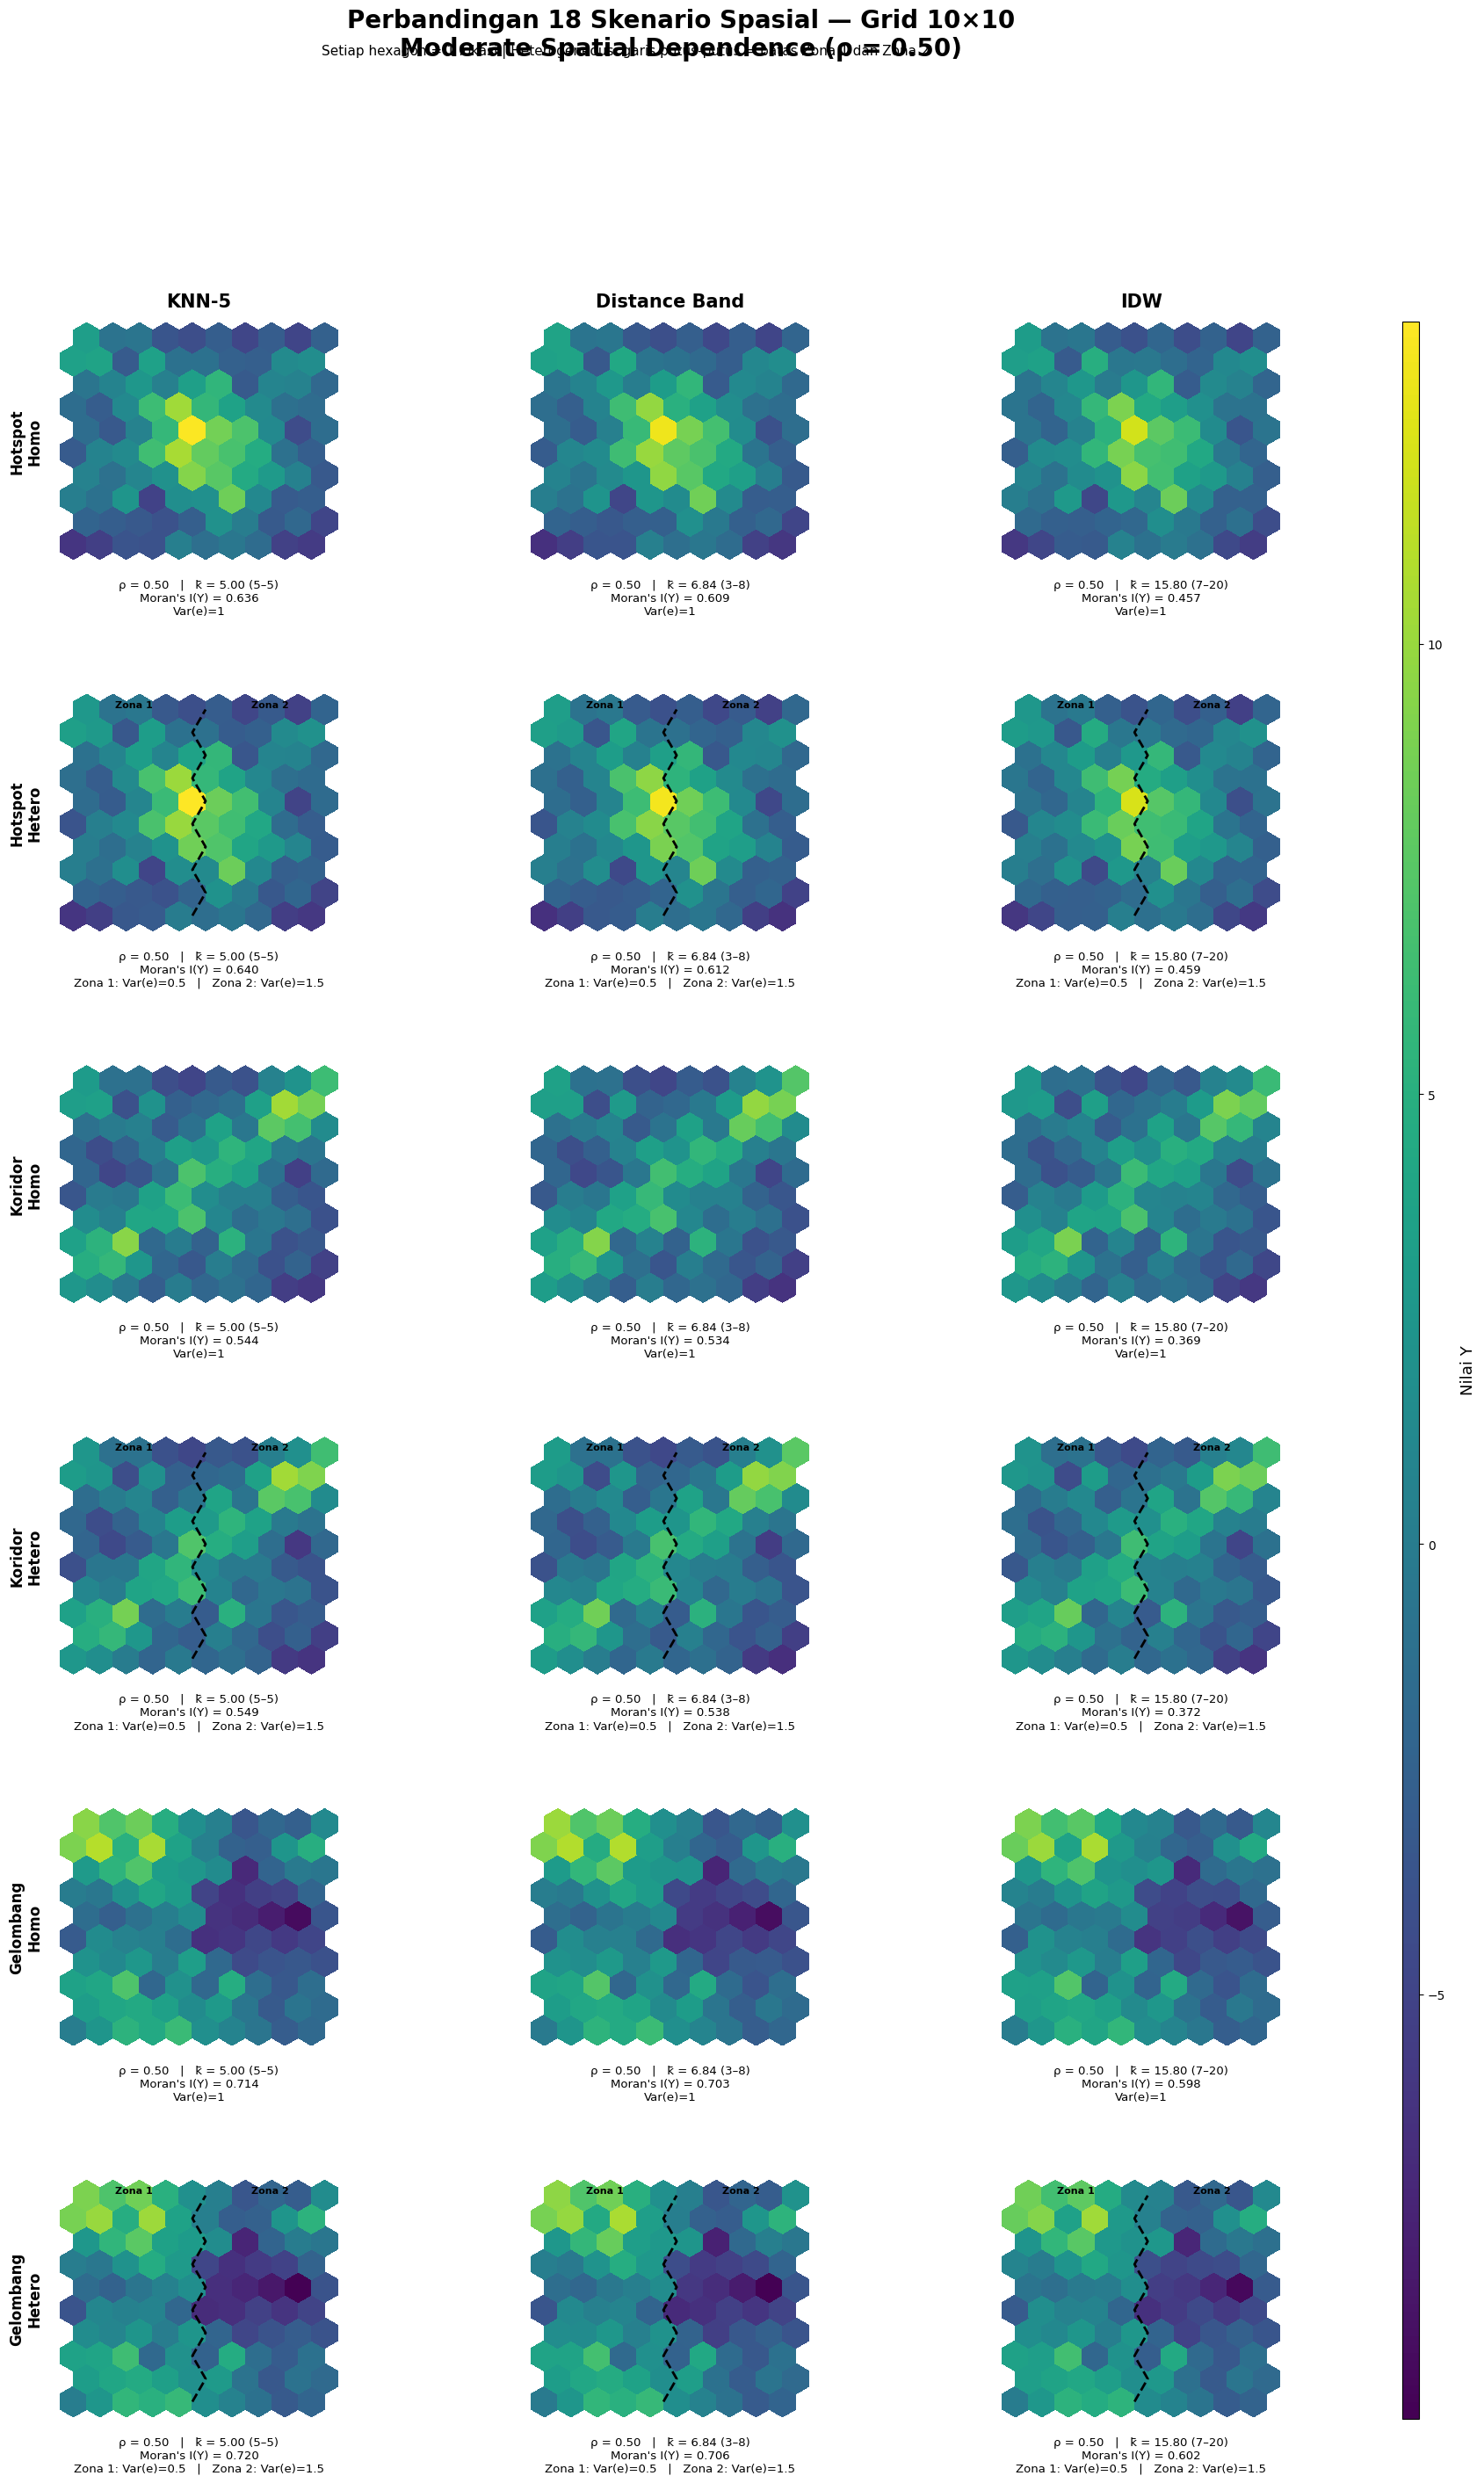


✅ VISUALISASI FINAL PASS
✅ rho dibaca dari data
✅ rho semua skenario = 0.50
✅ Heterogeneous punya garis batas zona
✅ Zona 1 = x <= 0.5 | Var(e)=0.5
✅ Zona 2 = x > 0.5  | Var(e)=1.5
✅ k-bar dari W asli
✅ Moran I(Y) dari data + W asli

📊 /content/FILE4_MODERATE_GRID10/VISUALISASI/HEXAGON_18_MODERATE_GRID10_ZONA_HETERO.png


In [15]:
# ================================================================
# FILE 4 — MODERATE rho = 0.50
# GRID10
#
# VISUALISASI FINAL 18 SKENARIO
# 3 KOLOM x 6 BARIS
#
# TAMBAHAN:
# ✅ Heterogeneous diberi garis batas Zona 1 | Zona 2
# ✅ Zona 1 = x <= 0.5  → Var(e) = 0.5
# ✅ Zona 2 = x >  0.5  → Var(e) = 1.5
# ✅ rho dibaca LANGSUNG dari data setiap skenario
# ✅ 1 lokasi = 1 hexagon
# ✅ TIDAK ada averaging / hexbin
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy.sparse as sp

from pathlib import Path
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
from matplotlib.gridspec import GridSpec


# ================================================================
# 1. DATA MODERATE GRID10
# ================================================================

if "DATA_MOD_GRID10" in globals():

    df = DATA_MOD_GRID10.copy()

elif "DATA_MODERATE_GRID10" in globals():

    df = DATA_MODERATE_GRID10.copy()

else:

    raise RuntimeError(
        "❌ DATA_MOD_GRID10 tidak ditemukan."
    )


assert "W_MOD10" in globals(), (
    "❌ W_MOD10 tidak ditemukan."
)


# ================================================================
# 2. PASTIKAN BENAR-BENAR rho = 0.50
# ================================================================

df = (

    df[
        np.isclose(
            df["Rho"].astype(float),
            0.50
        )
    ]

    .copy()
)


assert len(df) == 1800

assert df["Scenario_ID"].nunique() == 18

assert np.allclose(
    df["Rho"].astype(float),
    0.50
)


print("=" * 80)
print("VISUALISASI GRID10 MODERATE")
print("=" * 80)

print("Scenario :", df["Scenario_ID"].nunique())
print("Rows     :", len(df))
print("Rho data :", sorted(df["Rho"].unique()))

print(
    "\n✅ rho akan dibaca dari data, "
    "bukan ditentukan manual."
)


# ================================================================
# 3. W KEY
# ================================================================

def make_w_key(value):

    s = str(value).upper()

    if "KNN" in s:
        return "KNN5"

    if "DIST" in s:
        return "DISTANCE"

    if "IDW" in s:
        return "IDW"

    raise ValueError(
        f"W tidak dikenali: {value}"
    )


if "W_Key" not in df.columns:

    df["W_Key"] = (

        df["W_Method"]

        .apply(
            make_w_key
        )
    )


# ================================================================
# 4. LABEL
# ================================================================

def pattern_name(x):

    s = str(x).upper()

    if "HOT" in s:
        return "Hotspot"

    if "KOR" in s or "COR" in s:
        return "Koridor"

    if "GEL" in s or "WAVE" in s:
        return "Gelombang"

    return str(x)


def w_name(x):

    s = str(x).upper()

    if "KNN" in s:
        return "KNN-5"

    if "DIST" in s:
        return "Distance Band"

    if "IDW" in s:
        return "IDW"

    return str(x)


def error_name(x):

    s = str(x).upper()

    if "HET" in s:
        return "Heterogeneous"

    return "Homogeneous"


df["Pattern_plot"] = (
    df["Pattern"]
    .apply(pattern_name)
)

df["W_plot"] = (
    df["W_Method"]
    .apply(w_name)
)

df["Error_plot"] = (
    df["Error_Structure"]
    .apply(error_name)
)


# ================================================================
# 5. URUTAN PANEL
# ================================================================

PATTERNS = [
    "Hotspot",
    "Koridor",
    "Gelombang"
]


ERRORS = [
    "Homogeneous",
    "Heterogeneous"
]


W_METHODS = [
    "KNN-5",
    "Distance Band",
    "IDW"
]


ROWS = [

    (p, e)

    for p in PATTERNS

    for e in ERRORS
]


# ================================================================
# 6. JUMLAH TETANGGA DARI W ASLI
# ================================================================

def neighbor_counts_from_W(W):

    if sp.issparse(W):

        Wcsr = W.tocsr()

        counts = np.diff(
            Wcsr.indptr
        )

    else:

        arr = np.asarray(W)

        counts = np.count_nonzero(
            arr,
            axis=1
        )


    return np.asarray(
        counts,
        dtype=int
    )


# ================================================================
# 7. MORAN I(Y) DARI W ASLI
# ================================================================

def moran_I_original_W(
    y,
    W
):

    y = np.asarray(
        y,
        dtype=float
    )


    z = (
        y - np.mean(y)
    )


    denominator = float(
        z @ z
    )


    if denominator <= 0:
        return np.nan


    if sp.issparse(W):

        Wz = W @ z

        S0 = float(
            W.sum()
        )

    else:

        Warr = np.asarray(
            W,
            dtype=float
        )

        Wz = Warr @ z

        S0 = float(
            Warr.sum()
        )


    n = len(z)


    I = (

        (n / S0)

        *

        (
            float(z @ Wz)

            / denominator
        )
    )


    return float(I)


# ================================================================
# 8. WARNA GLOBAL
# ================================================================

VALUE_COL = "Y"


all_y = (

    df[VALUE_COL]

    .astype(float)

    .to_numpy()
)


vmin = float(
    np.nanmin(all_y)
)


vmax = float(
    np.nanmax(all_y)
)


norm = mpl.colors.Normalize(
    vmin=vmin,
    vmax=vmax
)


cmap = plt.get_cmap(
    "viridis"
)


# ================================================================
# 9. FUNGSI HEXAGON
#
# Return tambahan:
# geometry → dipakai untuk menggambar batas zona
# ================================================================

def draw_hexagon_data(
    ax,
    data,
    value_col,
    norm,
    cmap
):

    d = (

        data
        .sort_values(
            "Location_ID"
        )

        .reset_index(
            drop=True
        )
    )


    assert len(d) == 100


    # ------------------------------------------------------------
    # Koordinat asli
    # ------------------------------------------------------------

    x_values = np.sort(
        d["X_norm"].unique()
    )


    y_values = np.sort(
        d["Y_norm"].unique()
    )


    assert len(x_values) == 10
    assert len(y_values) == 10


    x_to_col = {

        float(value): i

        for i, value
        in enumerate(x_values)
    }


    y_to_row = {

        float(value): i

        for i, value
        in enumerate(y_values)
    }


    # ============================================================
    # GEOMETRI
    # ============================================================

    R = 1.0

    width = (
        np.sqrt(3) * R
    )

    vertical_step = (
        1.5 * R
    )


    rel_vertices = np.array([

        [0, R],

        [
            np.sqrt(3)/2 * R,
            0.5 * R
        ],

        [
            np.sqrt(3)/2 * R,
            -0.5 * R
        ],

        [0, -R],

        [
            -np.sqrt(3)/2 * R,
            -0.5 * R
        ],

        [
            -np.sqrt(3)/2 * R,
            0.5 * R
        ]

    ])


    patches = []

    values = []


    # ============================================================
    # 100 HEXAGON
    # ============================================================

    for _, obs in d.iterrows():


        col = x_to_col[
            float(
                obs["X_norm"]
            )
        ]


        row = y_to_row[
            float(
                obs["Y_norm"]
            )
        ]


        row_offset = (

            width / 2

            if row % 2 == 1

            else 0
        )


        x_center = (

            col * width

            + row_offset
        )


        y_center = (

            row
            * vertical_step
        )


        vertices = (

            rel_vertices

            + np.array([
                x_center,
                y_center
            ])
        )


        patches.append(

            Polygon(
                vertices,
                closed=True
            )
        )


        values.append(

            float(
                obs[value_col]
            )
        )


    collection = PatchCollection(

        patches,

        cmap=cmap,

        norm=norm,

        edgecolors="none",

        linewidths=0,

        antialiaseds=False
    )


    collection.set_array(
        np.asarray(values)
    )


    ax.add_collection(
        collection
    )


    max_x = (

        9 * width

        + width / 2
    )


    max_y = (

        9
        * vertical_step
    )


    ax.set_xlim(

        -width * 0.6,

        max_x
        + width * 0.6
    )


    ax.set_ylim(

        -R * 1.1,

        max_y
        + R * 1.1
    )


    ax.set_aspect(
        "equal"
    )


    ax.set_xticks([])

    ax.set_yticks([])


    for spine in ax.spines.values():

        spine.set_visible(False)


    geometry = {

        "R":
            R,

        "width":
            width,

        "vertical_step":
            vertical_step,

        "max_y":
            max_y,

        "x_values":
            x_values
    }


    return (
        collection,
        geometry
    )


# ================================================================
# 10. GARIS PEMISAH HETEROGENEOUS
#
# DGP ASLI:
#
# Zona 1 : x <= 0.5
# Zona 2 : x >  0.5
#
# Karena visual hexagon dibuat staggered,
# garis dibuat mengikuti posisi baris hexagon.
# ================================================================

def draw_hetero_boundary(
    ax,
    geometry
):

    width = (
        geometry[
            "width"
        ]
    )


    dy = (
        geometry[
            "vertical_step"
        ]
    )


    R = (
        geometry[
            "R"
        ]
    )


    # ------------------------------------------------------------
    # Grid10:
    # x = 0, 1/9, 2/9, ..., 1
    #
    # x <= .5 = kolom 0-4
    # x >  .5 = kolom 5-9
    #
    # Jadi batas berada antara kolom 4 dan 5.
    # ------------------------------------------------------------

    left_col = 4

    right_col = 5


    # titik batas untuk setiap row
    boundary_x = []

    boundary_y = []


    for row in range(10):

        row_offset = (

            width / 2

            if row % 2 == 1

            else 0
        )


        x_left = (

            left_col * width

            + row_offset
        )


        x_right = (

            right_col * width

            + row_offset
        )


        x_boundary = (

            x_left
            + x_right

        ) / 2


        y_center = (

            row
            * dy
        )


        boundary_x.append(
            x_boundary
        )


        boundary_y.append(
            y_center
        )


    # ------------------------------------------------------------
    # Perpanjang sedikit atas bawah
    # ------------------------------------------------------------

    bx = np.asarray(
        boundary_x
    )


    by = np.asarray(
        boundary_y
    )


    # ------------------------------------------------------------
    # Garis utama
    # ------------------------------------------------------------

    ax.plot(

        bx,

        by,

        color="black",

        linewidth=2.0,

        linestyle="--",

        zorder=20
    )


    # ------------------------------------------------------------
    # Label zona di bagian atas
    # ------------------------------------------------------------

    ax.text(

        0.27,

        0.97,

        "Zona 1",

        transform=
            ax.transAxes,

        ha="center",

        va="top",

        fontsize=8,

        fontweight="bold",

        color="black",

        zorder=30
    )


    ax.text(

        0.75,

        0.97,

        "Zona 2",

        transform=
            ax.transAxes,

        ha="center",

        va="top",

        fontsize=8,

        fontweight="bold",

        color="black",

        zorder=30
    )


# ================================================================
# 11. FIGURE
# ================================================================

fig = plt.figure(

    figsize=(
        21,
        31
    )
)


gs = GridSpec(

    nrows=6,

    ncols=4,

    figure=fig,

    width_ratios=[

        1,

        1,

        1,

        0.04
    ],

    wspace=0.16,

    hspace=0.55
)


axes = np.empty(

    (
        6,
        3
    ),

    dtype=object
)


for r in range(6):

    for c in range(3):

        axes[r, c] = (

            fig.add_subplot(
                gs[r, c]
            )
        )


cax = fig.add_subplot(
    gs[:, 3]
)


# ================================================================
# 12. LOOP 18 SKENARIO
# ================================================================

INFO_ROWS = []

last_collection = None


for r, (
    pattern,
    error
) in enumerate(
    ROWS
):


    for c, wmethod in enumerate(
        W_METHODS
    ):


        ax = axes[
            r,
            c
        ]


        # --------------------------------------------------------
        # DATA SKENARIO
        # --------------------------------------------------------

        d = (

            df[
                (
                    df["Pattern_plot"]
                    == pattern
                )

                &

                (
                    df["Error_plot"]
                    == error
                )

                &

                (
                    df["W_plot"]
                    == wmethod
                )
            ]

            .sort_values(
                "Location_ID"
            )

            .reset_index(
                drop=True
            )
        )


        assert len(d) == 100


        # ========================================================
        # RHO LANGSUNG DARI DATA
        # ========================================================

        rho_unique = (

            d["Rho"]

            .astype(float)

            .unique()
        )


        assert len(
            rho_unique
        ) == 1


        rho = float(
            rho_unique[0]
        )


        # jangan manual!
        assert np.isclose(
            rho,
            0.50
        )


        # ========================================================
        # W ASLI
        # ========================================================

        w_key = str(
            d["W_Key"].iloc[0]
        )


        W = (
            W_MOD10[
                w_key
            ]
        )


        # ========================================================
        # TETANGGA
        # ========================================================

        neighbor_counts = (

            neighbor_counts_from_W(
                W
            )
        )


        k_mean = float(
            neighbor_counts.mean()
        )


        k_min = int(
            neighbor_counts.min()
        )


        k_max = int(
            neighbor_counts.max()
        )


        # ========================================================
        # MORAN I(Y)
        # ========================================================

        y = (

            d["Y"]

            .to_numpy(
                dtype=float
            )
        )


        moran_y = (

            moran_I_original_W(
                y,
                W
            )
        )


        # ========================================================
        # HEXAGON
        # ========================================================

        (
            last_collection,
            geometry

        ) = draw_hexagon_data(

            ax=ax,

            data=d,

            value_col=
                VALUE_COL,

            norm=norm,

            cmap=cmap
        )


        # ========================================================
        # HETEROGENEOUS:
        # TAMBAH GARIS ZONA
        # ========================================================

        if (
            error
            == "Heterogeneous"
        ):

            draw_hetero_boundary(

                ax,

                geometry
            )


        # ========================================================
        # JUDUL KOLOM
        # ========================================================

        if r == 0:

            ax.set_title(

                wmethod,

                fontsize=15,

                fontweight="bold",

                pad=12
            )


        # ========================================================
        # LABEL BARIS
        # ========================================================

        if c == 0:

            error_short = (

                "Homo"

                if error
                == "Homogeneous"

                else "Hetero"
            )


            ax.set_ylabel(

                f"{pattern}\n"
                f"{error_short}",

                fontsize=12,

                fontweight="bold",

                labelpad=12
            )


        # ========================================================
        # INFORMASI DI BAWAH PANEL
        # ========================================================

        if (
            error
            == "Heterogeneous"
        ):

            info_text = (

                f"ρ = {rho:.2f}   |   "
                f"k̄ = {k_mean:.2f} "
                f"({k_min}–{k_max})"
                "\n"
                f"Moran's I(Y) = "
                f"{moran_y:.3f}"
                "\n"
                "Zona 1: Var(e)=0.5   |   "
                "Zona 2: Var(e)=1.5"
            )


        else:

            info_text = (

                f"ρ = {rho:.2f}   |   "
                f"k̄ = {k_mean:.2f} "
                f"({k_min}–{k_max})"
                "\n"
                f"Moran's I(Y) = "
                f"{moran_y:.3f}"
                "\n"
                "Var(e)=1"
            )


        ax.text(

            0.5,

            -0.075,

            info_text,

            transform=
                ax.transAxes,

            ha="center",

            va="top",

            fontsize=9.5
        )


        # ========================================================
        # SIMPAN INFORMASI
        # ========================================================

        INFO_ROWS.append({

            "Pattern":
                pattern,

            "Error":
                error,

            "W":
                wmethod,

            "Rho":
                rho,

            "Mean_Neighbors":
                k_mean,

            "Min_Neighbors":
                k_min,

            "Max_Neighbors":
                k_max,

            "Moran_I_Y":
                moran_y,

            "Zone_1":
                (
                    "x <= 0.5 | Var(e)=0.5"

                    if error
                    == "Heterogeneous"

                    else "Var(e)=1"
                ),

            "Zone_2":
                (
                    "x > 0.5 | Var(e)=1.5"

                    if error
                    == "Heterogeneous"

                    else "Var(e)=1"
                )
        })


# ================================================================
# 13. COLORBAR
# ================================================================

sm = mpl.cm.ScalarMappable(

    norm=norm,

    cmap=cmap
)


sm.set_array([])


cbar = fig.colorbar(

    sm,

    cax=cax
)


cbar.set_label(

    "Nilai Y",

    fontsize=13,

    labelpad=12
)


# ================================================================
# 14. JUDUL
# ================================================================

fig.suptitle(

    "Perbandingan 18 Skenario Spasial — Grid 10×10\n"
    "Moderate Spatial Dependence (ρ = 0.50)",

    fontsize=20,

    fontweight="bold",

    y=0.995
)


fig.text(

    0.47,

    0.978,

    (
        "Setiap hexagon = 1 lokasi | "
        "Heterogeneous: garis putus-putus = batas Zona 1 dan Zona 2"
    ),

    ha="center",

    fontsize=11
)


# ================================================================
# 15. TABLE IDENTITAS
# ================================================================

INFO_SPASIAL_MOD10 = pd.DataFrame(
    INFO_ROWS
)


# ================================================================
# 16. SAVE
# ================================================================

OUTPUT_DIR = Path(

    "/content/"
    "FILE4_MODERATE_GRID10/"
    "VISUALISASI"
)


OUTPUT_DIR.mkdir(

    parents=True,

    exist_ok=True
)


PNG_FILE = (

    OUTPUT_DIR

    / "HEXAGON_18_MODERATE_GRID10_ZONA_HETERO.png"
)


PDF_FILE = (

    OUTPUT_DIR

    / "HEXAGON_18_MODERATE_GRID10_ZONA_HETERO.pdf"
)


CSV_FILE = (

    OUTPUT_DIR

    / "IDENTITAS_SPASIAL_18_MODERATE_GRID10_ZONA.csv"
)


INFO_SPASIAL_MOD10.to_csv(

    CSV_FILE,

    index=False
)


plt.savefig(

    PNG_FILE,

    dpi=300,

    bbox_inches="tight"
)


plt.savefig(

    PDF_FILE,

    bbox_inches="tight"
)


plt.show()


# ================================================================
# 17. VALIDASI
# ================================================================

assert len(
    INFO_SPASIAL_MOD10
) == 18


assert np.allclose(

    INFO_SPASIAL_MOD10[
        "Rho"
    ],

    0.50
)


print(
    "\n"
    + "=" * 80
)

print(
    "✅ VISUALISASI FINAL PASS"
)

print(
    "=" * 80
)

print(
    "✅ rho dibaca dari data"
)

print(
    "✅ rho semua skenario = 0.50"
)

print(
    "✅ Heterogeneous punya garis batas zona"
)

print(
    "✅ Zona 1 = x <= 0.5 | Var(e)=0.5"
)

print(
    "✅ Zona 2 = x > 0.5  | Var(e)=1.5"
)

print(
    "✅ k-bar dari W asli"
)

print(
    "✅ Moran I(Y) dari data + W asli"
)

print(
    "\n📊",
    PNG_FILE
)

In [1]:
# ================================================================
# FILE 4 — MODERATE SPATIAL DEPENDENCE
# rho = 0.50
#
# CELL 1 — PERSIAPAN DATA
#
# SUMBER:
# FILE 1 / DATA_GRID10 ... DATA_GRID50
#
# TIDAK GENERATE DATA BARU
# HANYA FILTER rho = 0.50
# ================================================================

import os
import subprocess
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")


# ================================================================
# 1. KONFIGURASI
# ================================================================

SEED = 2026

RHO_TARGET = 0.50

STRENGTH = "Moderate"

REPO_URL = (
    "https://github.com/"
    "haniyathul/TESIS-HANIY.git"
)

REPO_DIR = Path(
    "/content/TESIS-HANIY"
)


# ================================================================
# 2. CLONE REPOSITORY JIKA NOTEBOOK BARU
# ================================================================

if not REPO_DIR.exists():

    print(
        "📥 Mengambil repository TESIS-HANIY..."
    )

    subprocess.run(
        [
            "git",
            "clone",
            REPO_URL,
            str(REPO_DIR)
        ],
        check=True
    )

    print(
        "✅ Repository berhasil di-clone"
    )

else:

    print(
        "✅ Repository sudah tersedia"
    )


# ================================================================
# 3. DIRECTORY
# ================================================================

DATA_DIR = (
    REPO_DIR
    / "data"
)

WEIGHT_DIR = (
    REPO_DIR
    / "weights"
)

ESF_DIR = (
    REPO_DIR
    / "esf"
)


OUTPUT_DIR_MODERATE = Path(
    "/content/FILE4_MODERATE"
)

OUTPUT_DIR_MODERATE.mkdir(
    parents=True,
    exist_ok=True
)


# ================================================================
# 4. GOOGLE DRIVE UNTUK CHECKPOINT
# ================================================================

try:

    from google.colab import drive

    if not Path(
        "/content/drive/MyDrive"
    ).exists():

        drive.mount(
            "/content/drive"
        )


    CHECKPOINT_ROOT_MODERATE = Path(
        "/content/drive/MyDrive/"
        "HANIY_CHECKPOINTS/"
        "FILE4_MODERATE"
    )

    CHECKPOINT_ROOT_MODERATE.mkdir(
        parents=True,
        exist_ok=True
    )


    print(
        "✅ Checkpoint FILE 4 → Google Drive"
    )


except Exception:

    CHECKPOINT_ROOT_MODERATE = (
        OUTPUT_DIR_MODERATE
        / "CHECKPOINT"
    )

    CHECKPOINT_ROOT_MODERATE.mkdir(
        parents=True,
        exist_ok=True
    )


    print(
        "⚠️ Checkpoint → /content"
    )


# ================================================================
# 5. PREDICTOR
# ================================================================

PREDICTOR_COLS = (

    ["X_spatial"]

    +

    [
        f"X{i}"
        for i in range(1, 20)
    ]
)


assert len(
    PREDICTOR_COLS
) == 20


# ================================================================
# 6. GRID YANG DIGUNAKAN
# ================================================================

GRID_INFO = {

    10: {
        "n": 100,
        "expected_rows": 1800
    },

    20: {
        "n": 400,
        "expected_rows": 7200
    },

    30: {
        "n": 900,
        "expected_rows": 16200
    },

    40: {
        "n": 1600,
        "expected_rows": 28800
    },

    50: {
        "n": 2500,
        "expected_rows": 45000
    }
}


# ================================================================
# 7. STORAGE
# ================================================================

DATA_MODERATE = {}

SCENARIO_IDS_MODERATE = {}


# ================================================================
# 8. REQUIRED COLUMNS
# ================================================================

REQUIRED_COLS = [

    "Scenario_ID",

    "Pattern",

    "W_Method",

    "Error_Structure",

    "Rho",

    "Y",

    "Location_ID",

    "X_norm",

    "Y_norm"

] + PREDICTOR_COLS


# ================================================================
# 9. NORMALISASI W METHOD
# ================================================================

def normalize_w_method(
    value
):

    s = str(
        value
    ).upper()


    if "KNN" in s:

        return "KNN5"


    if "DIST" in s:

        return "DISTANCE"


    if "IDW" in s:

        return "IDW"


    raise ValueError(
        f"W_Method tidak dikenali: {value}"
    )


# ================================================================
# 10. LOAD + FILTER rho = 0.50
# ================================================================

print(
    "\n"
    + "=" * 78
)

print(
    "FILE 4 — MODERATE"
)

print(
    "FILTER rho = 0.50"
)

print(
    "=" * 78
)


for grid_size, info in (
    GRID_INFO.items()
):


    # ------------------------------------------------------------
    # FILE
    # ------------------------------------------------------------

    data_file = (
        DATA_DIR
        / f"DATA_GRID{grid_size}.csv"
    )


    assert data_file.exists(), (
        f"❌ File tidak ditemukan:\n"
        f"{data_file}"
    )


    # ------------------------------------------------------------
    # LOAD
    # ------------------------------------------------------------

    df_all = pd.read_csv(
        data_file
    )


    # ------------------------------------------------------------
    # VALIDASI KOLOM
    # ------------------------------------------------------------

    missing = [

        c
        for c in REQUIRED_COLS
        if c not in df_all.columns
    ]


    assert not missing, (
        f"❌ GRID{grid_size} "
        f"kolom hilang: {missing}"
    )


    # ------------------------------------------------------------
    # FILTER rho = 0.50
    # ------------------------------------------------------------

    df = (

        df_all[
            np.isclose(
                df_all[
                    "Rho"
                ].astype(float),
                RHO_TARGET
            )
        ]

        .copy()
    )


    # ------------------------------------------------------------
    # NORMALISASI W
    # ------------------------------------------------------------

    df[
        "W_Key"
    ] = (

        df[
            "W_Method"
        ]

        .apply(
            normalize_w_method
        )
    )


    # ------------------------------------------------------------
    # SORT
    # ------------------------------------------------------------

    df = (

        df
        .sort_values(
            [
                "Scenario_ID",
                "Location_ID"
            ]
        )

        .reset_index(
            drop=True
        )
    )


    # ------------------------------------------------------------
    # SCENARIO IDS
    # ------------------------------------------------------------

    scenario_ids = (

        df[
            "Scenario_ID"
        ]

        .drop_duplicates()

        .tolist()
    )


    # ------------------------------------------------------------
    # VALIDASI 18 SCENARIO
    # ------------------------------------------------------------

    assert len(
        scenario_ids
    ) == 18, (
        f"❌ GRID{grid_size}: "
        f"harus 18 skenario, "
        f"ditemukan {len(scenario_ids)}"
    )


    # ------------------------------------------------------------
    # VALIDASI N PER SCENARIO
    # ------------------------------------------------------------

    scenario_size = (

        df
        .groupby(
            "Scenario_ID"
        )

        .size()
    )


    assert (
        scenario_size
        == info[
            "n"
        ]
    ).all(), (
        f"❌ GRID{grid_size}: "
        f"jumlah lokasi per skenario salah"
    )


    # ------------------------------------------------------------
    # VALIDASI TOTAL ROW
    # ------------------------------------------------------------

    assert len(
        df
    ) == info[
        "expected_rows"
    ], (
        f"❌ GRID{grid_size}: "
        f"expected "
        f"{info['expected_rows']} rows, "
        f"ditemukan {len(df)}"
    )


    # ------------------------------------------------------------
    # RHO HARUS 0.50
    # ------------------------------------------------------------

    assert np.allclose(
        df[
            "Rho"
        ].astype(float),
        0.50
    )


    # ------------------------------------------------------------
    # SIMPAN
    # ------------------------------------------------------------

    DATA_MODERATE[
        grid_size
    ] = df


    SCENARIO_IDS_MODERATE[
        grid_size
    ] = scenario_ids


    # objek terpisah supaya gampang dipakai
    globals()[
        f"DATA_MODERATE_GRID{grid_size}"
    ] = df


    globals()[
        f"SCENARIO_IDS_GRID{grid_size}_MODERATE"
    ] = scenario_ids


    # ------------------------------------------------------------
    # REPORT
    # ------------------------------------------------------------

    print(
        f"\n✅ GRID{grid_size}"
    )


    print(
        f"   Grid              : "
        f"{grid_size} x {grid_size}"
    )


    print(
        f"   N / scenario      : "
        f"{info['n']}"
    )


    print(
        f"   Scenario Moderate : "
        f"{len(scenario_ids)}"
    )


    print(
        f"   Rows              : "
        f"{len(df)}"
    )


    print(
        f"   Rho               : "
        f"{df['Rho'].unique()}"
    )


# ================================================================
# 11. TOTAL FILE 4
# ================================================================

TOTAL_SCENARIOS_MODERATE = sum(

    len(
        SCENARIO_IDS_MODERATE[
            grid
        ]
    )

    for grid
    in GRID_INFO
)


TOTAL_ROWS_MODERATE = sum(

    len(
        DATA_MODERATE[
            grid
        ]
    )

    for grid
    in GRID_INFO
)


assert (
    TOTAL_SCENARIOS_MODERATE
    == 90
)


assert (
    TOTAL_ROWS_MODERATE
    == 99000
)


# ================================================================
# 12. SUMMARY VALIDASI
# ================================================================

VALIDASI_MODERATE = []


for grid_size, info in (
    GRID_INFO.items()
):

    df = (
        DATA_MODERATE[
            grid_size
        ]
    )


    VALIDASI_MODERATE.append({

        "Grid":
            f"{grid_size}x{grid_size}",

        "N":
            info["n"],

        "Rho":
            0.50,

        "Strength":
            "Moderate",

        "Scenario":
            df[
                "Scenario_ID"
            ].nunique(),

        "Rows":
            len(df),

        "Patterns":
            df[
                "Pattern"
            ].nunique(),

        "W_Methods":
            df[
                "W_Method"
            ].nunique(),

        "Error_Structures":
            df[
                "Error_Structure"
            ].nunique(),

        "Predictors":
            len(
                PREDICTOR_COLS
            )
    })


VALIDASI_MODERATE = pd.DataFrame(
    VALIDASI_MODERATE
)


# ================================================================
# 13. TAMPILKAN SUMMARY
# ================================================================

print(
    "\n"
    + "=" * 78
)

print(
    "FILE 4 — MODERATE DATA READY"
)

print(
    "=" * 78
)


print(
    VALIDASI_MODERATE.to_string(
        index=False
    )
)


print(
    "\n"
    + "-" * 78
)


print(
    "TOTAL SCENARIO MODERATE :",
    TOTAL_SCENARIOS_MODERATE
)


print(
    "TOTAL ROW MODERATE      :",
    TOTAL_ROWS_MODERATE
)


print(
    "RHO                     :",
    RHO_TARGET
)


print(
    "STRENGTH                :",
    STRENGTH
)


print(
    "PREDICTOR               :",
    len(
        PREDICTOR_COLS
    )
)


print(
    "\n✅ FILE 4 MODERATE — DATA PREPARATION: PASS"
)

📥 Mengambil repository TESIS-HANIY...
✅ Repository berhasil di-clone
Mounted at /content/drive
✅ Checkpoint FILE 4 → Google Drive

FILE 4 — MODERATE
FILTER rho = 0.50

✅ GRID10
   Grid              : 10 x 10
   N / scenario      : 100
   Scenario Moderate : 18
   Rows              : 1800
   Rho               : [0.5]

✅ GRID20
   Grid              : 20 x 20
   N / scenario      : 400
   Scenario Moderate : 18
   Rows              : 7200
   Rho               : [0.5]

✅ GRID30
   Grid              : 30 x 30
   N / scenario      : 900
   Scenario Moderate : 18
   Rows              : 16200
   Rho               : [0.5]

✅ GRID40
   Grid              : 40 x 40
   N / scenario      : 1600
   Scenario Moderate : 18
   Rows              : 28800
   Rho               : [0.5]

✅ GRID50
   Grid              : 50 x 50
   N / scenario      : 2500
   Scenario Moderate : 18
   Rows              : 45000
   Rho               : [0.5]

FILE 4 — MODERATE DATA READY
 Grid    N  Rho Strength  Scenario  Rows  P

In [2]:
# ================================================================
# FILE 4 — MODERATE rho = 0.50
# GRID10 (10 x 10)
#
# MODELING 5 MODEL — SATU CELL
#
# URUTAN:
# 1. XGBOOST              → 18 scenario
# 2. ESF-XGBOOST MORAN    → 18 scenario
# 3. ESF-XGBOOST LASSO    → 18 scenario
# 4. ESF-XGBOOST STEPWISE → 18 scenario
#    Candidate = POSITIVE EV ONLY
# 5. ESF-XGBOOST SHAP     → 18 scenario
#    Candidate = ALL 99 EV
#
# CHECKPOINT SETIAP OUTER FOLD
# ================================================================

import os
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp

import xgboost as xgb
from xgboost import XGBRegressor

from sklearn.cluster import KMeans
from sklearn.linear_model import LassoCV
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)


# ================================================================
# 0. CEK DATA MODERATE DARI CELL SEBELUMNYA
# ================================================================

assert "DATA_MODERATE_GRID10" in globals(), (
    "❌ Jalankan persiapan FILE 4 Moderate dulu."
)

assert "SCENARIO_IDS_GRID10_MODERATE" in globals()

assert "WEIGHT_DIR" in globals()

assert "ESF_DIR" in globals()

assert "CHECKPOINT_ROOT_MODERATE" in globals()


DATA_MOD_GRID10 = (
    DATA_MODERATE_GRID10
    .copy()
)

SCENARIO_IDS_MOD_GRID10 = (
    SCENARIO_IDS_GRID10_MODERATE
)


RHO_MODERATE = 0.50

N_LOCATION = 100
N_EV_TOTAL = 99


PREDICTOR_COLS_MOD10 = (
    ["X_spatial"]
    + [f"X{i}" for i in range(1, 20)]
)


# ================================================================
# 1. MODEL NAMES
# ================================================================

MODEL_NAMES_MOD10 = [

    "XGBoost",

    "ESF-XGBoost Moran",

    "ESF-XGBoost LASSO",

    "ESF-XGBoost Stepwise",

    "ESF-XGBoost SHAP"
]


# ================================================================
# 2. CHECKPOINT
# ================================================================

CHECKPOINT_DIR_MOD10 = (
    CHECKPOINT_ROOT_MODERATE
    / "GRID10"
)

CHECKPOINT_DIR_MOD10.mkdir(
    parents=True,
    exist_ok=True
)


CHECKPOINT_MOD10 = (
    CHECKPOINT_DIR_MOD10
    / "MODERATE_GRID10_5MODEL.pkl"
)


CHECKPOINT_VERSION_MOD10 = (
    "MODERATE_GRID10_5MODEL_POSSTEP_V1"
)


print("=" * 80)
print("FILE 4 MODERATE — GRID10")
print("rho = 0.50")
print("=" * 80)

print(
    "Checkpoint:",
    CHECKPOINT_MOD10
)


# ================================================================
# 3. OUTER SPATIAL CV = 5 FOLD
# ================================================================

FIRST_SCENARIO = (
    SCENARIO_IDS_MOD_GRID10[0]
)


BASE_LOCATION = (

    DATA_MOD_GRID10[
        DATA_MOD_GRID10[
            "Scenario_ID"
        ] == FIRST_SCENARIO
    ]

    .sort_values(
        "Location_ID"
    )

    .reset_index(drop=True)
)


BASE_COORD = (

    BASE_LOCATION[
        [
            "X_norm",
            "Y_norm"
        ]
    ]

    .to_numpy()
)


OUTER_LABEL = KMeans(

    n_clusters=5,

    random_state=2026,

    n_init=20

).fit_predict(
    BASE_COORD
)


FOLD_MAP_MOD10 = dict(

    zip(

        BASE_LOCATION[
            "Location_ID"
        ].tolist(),

        OUTER_LABEL.tolist()
    )
)


DATA_MOD_GRID10[
    "Outer_Fold"
] = (

    DATA_MOD_GRID10[
        "Location_ID"
    ]

    .map(
        FOLD_MAP_MOD10
    )

    .astype(int)
)


print(
    "✅ Outer Spatial CV = 5 fold"
)


# ================================================================
# 4. CARI FILE NPZ GRID10
# ================================================================

def find_npz_mod10(
    folder,
    method
):

    candidates = []


    for f in Path(folder).glob(
        "*.npz"
    ):

        name = f.name.upper()


        if "GRID10" not in name:

            continue


        if method == "KNN5":

            ok = (
                "KNN"
                in name
            )


        elif method == "DISTANCE":

            ok = (
                "DIST"
                in name
            )


        elif method == "IDW":

            ok = (
                "IDW"
                in name
            )


        else:

            ok = False


        if ok:

            candidates.append(
                f
            )


    assert candidates, (
        f"❌ GRID10 {method} "
        f"tidak ditemukan di {folder}"
    )


    return sorted(
        candidates
    )[0]


# ================================================================
# 5. LOAD W
# ================================================================

def load_W_mod10(
    path
):

    try:

        return (
            sp.load_npz(
                path
            )
            .tocsr()
            .astype(float)
        )

    except Exception:

        pass


    obj = np.load(
        path,
        allow_pickle=True
    )


    for key in obj.files:

        arr = np.asarray(
            obj[key]
        )


        if (
            arr.ndim == 2
            and
            arr.shape == (100, 100)
        ):

            return sp.csr_matrix(
                arr.astype(float)
            )


    raise ValueError(
        f"❌ W tidak ditemukan: {path}"
    )


# ================================================================
# 6. LOAD ESF
# ================================================================

def load_ESF_mod10(
    path
):

    obj = np.load(
        path,
        allow_pickle=True
    )


    E = None
    eig = None


    # eigenvectors
    for key in [
        "eigenvectors",
        "eigenvector",
        "EV",
        "E",
        "vectors"
    ]:

        if key in obj.files:

            arr = np.asarray(
                obj[key]
            )

            if arr.ndim == 2:

                E = arr
                break


    if E is None:

        for key in obj.files:

            arr = np.asarray(
                obj[key]
            )


            if (
                arr.ndim == 2
                and
                (
                    arr.shape[0] == 100
                    or
                    arr.shape[1] == 100
                )
            ):

                E = arr
                break


    assert E is not None, (
        f"❌ Eigenvector tidak ditemukan: {path}"
    )


    if E.shape[0] != 100:

        E = E.T


    # eigenvalues
    for key in [
        "eigenvalues",
        "eigenvalue",
        "values",
        "evals",
        "lambda"
    ]:

        if key in obj.files:

            arr = np.asarray(
                obj[key]
            ).reshape(-1)


            if len(
                arr
            ) == E.shape[1]:

                eig = arr
                break


    if eig is None:

        for key in obj.files:

            arr = np.asarray(
                obj[key]
            )


            if (
                arr.ndim == 1
                and
                len(arr) == E.shape[1]
            ):

                eig = arr
                break


    assert eig is not None, (
        f"❌ Eigenvalue tidak ditemukan: {path}"
    )


    return (

        E.astype(
            np.float32
        ),

        eig.astype(float)
    )


# ================================================================
# 7. LOAD W + ESF
# ================================================================

W_MOD10 = {}
ESF_MOD10 = {}


for method in [

    "KNN5",
    "DISTANCE",
    "IDW"
]:

    w_file = (
        find_npz_mod10(
            WEIGHT_DIR,
            method
        )
    )


    esf_file = (
        find_npz_mod10(
            ESF_DIR,
            method
        )
    )


    W_MOD10[
        method
    ] = load_W_mod10(
        w_file
    )


    (
        E,
        eigenvalues
    ) = load_ESF_mod10(
        esf_file
    )


    assert E.shape == (
        100,
        99
    )


    ESF_MOD10[
        method
    ] = {

        "E":
            E,

        "eigenvalues":
            eigenvalues
    }


    n_positive = int(
        np.sum(
            eigenvalues > 0
        )
    )


    print(

        f"✅ {method:8s} "
        f"| EV=99 "
        f"| Positive EV={n_positive}"
    )


# ================================================================
# 8. 18 HYPERPARAMETER
# ================================================================

hyper_rows = []

hid = 1


for n_estimators in [
    200,
    300
]:

    for learning_rate in [
        0.03,
        0.05,
        0.10
    ]:

        for max_depth in [
            2,
            3,
            4
        ]:

            hyper_rows.append({

                "Hyper_ID":
                    f"H{hid:02d}",

                "n_estimators":
                    n_estimators,

                "learning_rate":
                    learning_rate,

                "max_depth":
                    max_depth
            })


            hid += 1


HYPER_GRID_MOD10 = pd.DataFrame(
    hyper_rows
)


assert len(
    HYPER_GRID_MOD10
) == 18


# ================================================================
# 9. FIXED XGBOOST
# ================================================================

XGB_FIXED_MOD10 = {

    "objective":
        "reg:squarederror",

    "min_child_weight":
        1,

    "subsample":
        0.8,

    "colsample_bytree":
        0.8,

    "reg_alpha":
        0,

    "reg_lambda":
        1,

    "gamma":
        0,

    "tree_method":
        "hist",

    "eval_metric":
        "rmse",

    "random_state":
        2026,

    "n_jobs":
        -1
}


# ================================================================
# 10. FUNCTIONS
# ================================================================

def rmse_mod10(
    y_true,
    y_pred
):

    return float(

        np.sqrt(

            mean_squared_error(
                y_true,
                y_pred
            )
        )
    )


def make_xgb_mod10(
    config
):

    return XGBRegressor(

        n_estimators=int(
            config[
                "n_estimators"
            ]
        ),

        learning_rate=float(
            config[
                "learning_rate"
            ]
        ),

        max_depth=int(
            config[
                "max_depth"
            ]
        ),

        **XGB_FIXED_MOD10
    )


def inner_fold_mod10(
    coords
):

    return KMeans(

        n_clusters=3,

        random_state=2026,

        n_init=20

    ).fit_predict(
        coords
    )


# ================================================================
# 11. TUNING
# ================================================================

def tune_xgb_mod10(
    X,
    y,
    labels
):

    results = []


    for _, hp in (
        HYPER_GRID_MOD10
        .iterrows()
    ):

        cfg = hp.to_dict()

        scores = []


        for fold in sorted(
            np.unique(
                labels
            )
        ):

            tr = (
                labels != fold
            )

            va = (
                labels == fold
            )


            model = (
                make_xgb_mod10(
                    cfg
                )
            )


            model.fit(
                X[tr],
                y[tr]
            )


            pred = model.predict(
                X[va]
            )


            scores.append(
                rmse_mod10(
                    y[va],
                    pred
                )
            )


        results.append({

            "Hyper_ID":
                cfg[
                    "Hyper_ID"
                ],

            "Mean_RMSE":
                float(
                    np.mean(
                        scores
                    )
                ),

            "config":
                cfg
        })


    results = sorted(

        results,

        key=lambda z: (

            z[
                "Mean_RMSE"
            ],

            z[
                "Hyper_ID"
            ]
        )
    )


    best = results[0]


    return (

        best[
            "Hyper_ID"
        ],

        best[
            "config"
        ],

        best[
            "Mean_RMSE"
        ]
    )


# ================================================================
# 12. FINAL FIT
# ================================================================

def fit_final_mod10(
    Xtr,
    ytr,
    Xte,
    labels
):

    (
        best_hid,
        best_cfg,
        best_cv
    ) = tune_xgb_mod10(

        Xtr,
        ytr,
        labels
    )


    model = (
        make_xgb_mod10(
            best_cfg
        )
    )


    model.fit(
        Xtr,
        ytr
    )


    pred = model.predict(
        Xte
    )


    return (

        pred,

        best_hid,

        best_cfg,

        best_cv
    )


# ================================================================
# 13. CROSS-FITTED BASELINE RESIDUAL
# ================================================================

def crossfit_residual_mod10(
    X,
    y,
    labels,
    config
):

    pred = np.full(
        len(y),
        np.nan
    )


    for fold in sorted(
        np.unique(
            labels
        )
    ):

        tr = (
            labels != fold
        )

        va = (
            labels == fold
        )


        model = (
            make_xgb_mod10(
                config
            )
        )


        model.fit(
            X[tr],
            y[tr]
        )


        pred[
            va
        ] = model.predict(
            X[va]
        )


    assert not np.isnan(
        pred
    ).any()


    return (

        pred,

        y - pred
    )


# ================================================================
# 14. MORAN SELECTION
# ================================================================

def select_moran_mod10(
    eigenvalues
):

    eig = np.asarray(
        eigenvalues,
        dtype=float
    )


    positive = eig[
        eig > 0
    ]


    if len(
        positive
    ) == 0:

        return np.array(
            [],
            dtype=int
        )


    threshold = (

        0.25

        * np.max(
            positive
        )
    )


    return np.where(

        (eig > 0)

        &

        (eig >= threshold)

    )[0].astype(int)


# ================================================================
# 15. LASSO — ALL 99 EV
# ================================================================

def select_lasso_mod10(
    E,
    residual,
    labels
):

    splits = []


    for fold in sorted(
        np.unique(
            labels
        )
    ):

        tr = np.where(
            labels != fold
        )[0]


        va = np.where(
            labels == fold
        )[0]


        splits.append(
            (
                tr,
                va
            )
        )


    lasso = LassoCV(

        cv=splits,

        fit_intercept=True,

        max_iter=50000,

        n_jobs=-1
    )


    lasso.fit(
        E,
        residual
    )


    selected = np.where(

        np.abs(
            lasso.coef_
        )

        > 1e-8

    )[0]


    return (

        selected.astype(int),

        float(
            lasso.alpha_
        )
    )


# ================================================================
# 16. STEPWISE POSITIVE-EV
# Vectorized Forward Spatial CV
# ================================================================

def subset_cv_rmse_mod10(
    E,
    residual,
    labels,
    selected
):

    scores = []


    for fold in sorted(
        np.unique(
            labels
        )
    ):

        tr = (
            labels != fold
        )

        va = (
            labels == fold
        )


        ytr = residual[
            tr
        ]


        yva = residual[
            va
        ]


        if len(
            selected
        ) == 0:

            pred = np.full(

                np.sum(
                    va
                ),

                np.mean(
                    ytr
                )
            )


        else:

            Dtr = np.column_stack([

                np.ones(
                    np.sum(
                        tr
                    )
                ),

                E[
                    tr
                ][:, selected]
            ])


            Dva = np.column_stack([

                np.ones(
                    np.sum(
                        va
                    )
                ),

                E[
                    va
                ][:, selected]
            ])


            beta = np.linalg.lstsq(

                Dtr,

                ytr,

                rcond=None

            )[0]


            pred = (
                Dva
                @ beta
            )


        scores.append(
            rmse_mod10(
                yva,
                pred
            )
        )


    return float(
        np.mean(
            scores
        )
    )


def candidate_scores_mod10(
    E,
    residual,
    labels,
    selected,
    remaining
):

    score_sum = np.zeros(
        len(
            remaining
        ),
        dtype=float
    )


    E_rem = E[
        :,
        remaining
    ].astype(
        np.float64,
        copy=False
    )


    unique_folds = sorted(
        np.unique(
            labels
        )
    )


    for fold in unique_folds:

        tr = (
            labels != fold
        )

        va = (
            labels == fold
        )


        ytr = residual[
            tr
        ].astype(
            np.float64,
            copy=False
        )


        yva = residual[
            va
        ].astype(
            np.float64,
            copy=False
        )


        if len(
            selected
        ) == 0:

            Dtr = np.ones(
                (
                    np.sum(tr),
                    1
                )
            )


            Dva = np.ones(
                (
                    np.sum(va),
                    1
                )
            )


        else:

            Dtr = np.column_stack([

                np.ones(
                    np.sum(
                        tr
                    )
                ),

                E[
                    tr
                ][:, selected]
            ])


            Dva = np.column_stack([

                np.ones(
                    np.sum(
                        va
                    )
                ),

                E[
                    va
                ][:, selected]
            ])


        beta_y = np.linalg.lstsq(

            Dtr,

            ytr,

            rcond=None

        )[0]


        base_pred = (
            Dva
            @ beta_y
        )


        residual_train = (

            ytr

            -

            Dtr
            @ beta_y
        )


        Xtr_rem = (
            E_rem[
                tr
            ]
        )


        Xva_rem = (
            E_rem[
                va
            ]
        )


        B = np.linalg.lstsq(

            Dtr,

            Xtr_rem,

            rcond=None

        )[0]


        Utr = (

            Xtr_rem

            -

            Dtr @ B
        )


        Uva = (

            Xva_rem

            -

            Dva @ B
        )


        denominator = np.sum(

            Utr * Utr,

            axis=0
        )


        numerator = (

            Utr.T

            @ residual_train
        )


        alpha = np.zeros_like(
            numerator
        )


        valid = (
            denominator
            > 1e-12
        )


        alpha[
            valid
        ] = (

            numerator[
                valid
            ]

            /

            denominator[
                valid
            ]
        )


        pred_matrix = (

            base_pred[
                :,
                None
            ]

            +

            Uva

            * alpha[
                None,
                :
            ]
        )


        error = (

            yva[
                :,
                None
            ]

            -

            pred_matrix
        )


        score_sum += np.sqrt(

            np.mean(

                error
                * error,

                axis=0
            )
        )


    return (

        score_sum

        /

        len(
            unique_folds
        )
    )


def forward_stepwise_mod10(
    E_positive,
    residual,
    labels,
    positive_original_idx
):

    selected_local = []

    remaining = list(
        range(
            E_positive.shape[1]
        )
    )


    current_rmse = (

        subset_cv_rmse_mod10(

            E_positive,

            residual,

            labels,

            selected=[]
        )
    )


    step = 0


    while len(
        remaining
    ) > 0:

        scores = (
            candidate_scores_mod10(

                E_positive,

                residual,

                labels,

                selected_local,

                remaining
            )
        )


        best_pos = int(
            np.argmin(
                scores
            )
        )


        best_local = (
            remaining[
                best_pos
            ]
        )


        best_score = float(
            scores[
                best_pos
            ]
        )


        improvement = (

            current_rmse

            -

            best_score
        )


        if improvement > 1e-10:

            selected_local.append(
                best_local
            )


            remaining.pop(
                best_pos
            )


            current_rmse = (
                best_score
            )


            step += 1


            original_ev = int(

                positive_original_idx[
                    best_local
                ]
            )


            print(

                f"      Step {step:02d} "
                f"→ EV{original_ev + 1} "
                f"| CV={current_rmse:.4f}",

                flush=True
            )


        else:

            break


    if len(
        selected_local
    ) == 0:

        selected_original = np.array(
            [],
            dtype=int
        )


    else:

        selected_original = (

            positive_original_idx[
                np.asarray(
                    selected_local,
                    dtype=int
                )
            ]
        )


    return (

        selected_original,

        float(
            current_rmse
        )
    )


# ================================================================
# 17. SHAP — ALL 99 EV
# ================================================================

def select_shap_mod10(
    E,
    residual,
    labels
):

    # Selector tuning sendiri
    (
        selector_hid,
        selector_cfg,
        selector_cv
    ) = tune_xgb_mod10(

        E,

        residual,

        labels
    )


    selector = (
        make_xgb_mod10(
            selector_cfg
        )
    )


    selector.fit(
        E,
        residual
    )


    dm = xgb.DMatrix(
        E
    )


    shap_values = (

        selector
        .get_booster()
        .predict(

            dm,

            pred_contribs=True
        )
    )


    # terakhir = bias
    shap_values = (
        shap_values[
            :,
            :-1
        ]
    )


    importance = np.mean(

        np.abs(
            shap_values
        ),

        axis=0
    )


    total = float(
        np.sum(
            importance
        )
    )


    if total <= 0:

        selected = np.array(
            [],
            dtype=int
        )


    else:

        order = np.argsort(
            importance
        )[::-1]


        cumulative = (

            np.cumsum(
                importance[
                    order
                ]
            )

            / total
        )


        k = (

            int(

                np.searchsorted(
                    cumulative,
                    0.90
                )
            )

            + 1
        )


        selected = (
            order[
                :k
            ]
            .astype(int)
        )


    return (

        selected,

        selector_hid,

        selector_cfg,

        float(
            selector_cv
        )
    )


# ================================================================
# 18. CHECKPOINT
# ================================================================

def save_checkpoint_mod10(
    state
):

    tmp = Path(
        str(
            CHECKPOINT_MOD10
        )
        + ".tmp"
    )


    with open(
        tmp,
        "wb"
    ) as f:

        pickle.dump(

            state,

            f,

            protocol=
                pickle.HIGHEST_PROTOCOL
        )


    os.replace(
        tmp,
        CHECKPOINT_MOD10
    )


def done_key_mod10(
    model,
    sid,
    fold
):

    return (
        f"{model}"
        f"|||{sid}"
        f"|||{fold}"
    )


def baseline_key_mod10(
    sid,
    fold
):

    return (
        f"{sid}"
        f"|||{fold}"
    )


# ================================================================
# 19. LOAD CHECKPOINT
# ================================================================

state = None


if CHECKPOINT_MOD10.exists():

    try:

        with open(
            CHECKPOINT_MOD10,
            "rb"
        ) as f:

            old_state = (
                pickle.load(
                    f
                )
            )


        if (
            old_state.get(
                "version"
            )
            == CHECKPOINT_VERSION_MOD10
        ):

            state = old_state


            print(
                "\n✅ Checkpoint Grid10 Moderate ditemukan"
            )


            print(
                "✅ Yang selesai akan di-SKIP"
            )


    except Exception:

        state = None


if state is None:

    state = {

        "version":
            CHECKPOINT_VERSION_MOD10,

        "predictions":
            {},

        "done_keys":
            set(),

        "fold_rows":
            [],

        "baseline_config":
            {},

        "baseline_residual":
            {}
    }


# ================================================================
# 20. INIT PREDICTIONS
# ================================================================

for sid in SCENARIO_IDS_MOD_GRID10:

    if sid not in state[
        "predictions"
    ]:

        state[
            "predictions"
        ][sid] = {}


    for model_name in (
        MODEL_NAMES_MOD10
    ):

        if (
            model_name
            not in
            state[
                "predictions"
            ][sid]
        ):

            state[
                "predictions"
            ][sid][
                model_name
            ] = np.full(
                100,
                np.nan
            )


# ================================================================
# 21. ANTI DUPLIKAT FOLD ROW
# ================================================================

def add_fold_row_mod10(
    row
):

    state[
        "fold_rows"
    ] = [

        r

        for r in state[
            "fold_rows"
        ]

        if not (

            r[
                "Scenario_ID"
            ]
            == row[
                "Scenario_ID"
            ]

            and

            r[
                "Model"
            ]
            == row[
                "Model"
            ]

            and

            r[
                "Fold"
            ]
            == row[
                "Fold"
            ]
        )
    ]


    state[
        "fold_rows"
    ].append(
        row
    )


# ================================================================
# 22. MAIN LOOP — MODEL TERLUAR
# ================================================================

for model_no, model_name in enumerate(

    MODEL_NAMES_MOD10,

    start=1
):


    print(
        "\n\n"
        + "=" * 84
    )


    print(

        f"MODEL {model_no}/5 "
        f"— {model_name.upper()}"
    )


    print(
        "=" * 84
    )


    # ============================================================
    # 18 SCENARIO
    # ============================================================

    for scenario_no, sid in enumerate(

        SCENARIO_IDS_MOD_GRID10,

        start=1
    ):


        df_s = (

            DATA_MOD_GRID10[
                DATA_MOD_GRID10[
                    "Scenario_ID"
                ]
                == sid
            ]

            .sort_values(
                "Location_ID"
            )

            .reset_index(
                drop=True
            )
        )


        assert len(
            df_s
        ) == 100


        X_base = (

            df_s[
                PREDICTOR_COLS_MOD10
            ]

            .to_numpy(
                dtype=np.float32
            )
        )


        y = (

            df_s[
                "Y"
            ]

            .to_numpy(
                dtype=np.float32
            )
        )


        coords = (

            df_s[
                [
                    "X_norm",
                    "Y_norm"
                ]
            ]

            .to_numpy(
                dtype=float
            )
        )


        outer_fold = (

            df_s[
                "Outer_Fold"
            ]

            .to_numpy(
                dtype=int
            )
        )


        w_key = (
            df_s[
                "W_Key"
            ].iloc[0]
        )


        E = (

            ESF_MOD10[
                w_key
            ][
                "E"
            ]
        )


        eigenvalues = (

            ESF_MOD10[
                w_key
            ][
                "eigenvalues"
            ]
        )


        print(
            "\n"
            + "-" * 84
        )


        print(

            f"Scenario "
            f"{scenario_no:02d}/18 "
            f"| {sid}"
        )


        print(

            f"Pattern="
            f"{df_s['Pattern'].iloc[0]} "

            f"| W="
            f"{df_s['W_Method'].iloc[0]} "

            f"| Error="
            f"{df_s['Error_Structure'].iloc[0]}"
        )


        # ========================================================
        # 5 OUTER FOLD
        # ========================================================

        for fold in range(5):

            dkey = (
                done_key_mod10(

                    model_name,

                    sid,

                    fold
                )
            )


            if dkey in state[
                "done_keys"
            ]:

                print(

                    f"  Fold "
                    f"{fold + 1}/5 "
                    f"→ sudah selesai ✅"
                )

                continue


            train_idx = np.where(
                outer_fold != fold
            )[0]


            test_idx = np.where(
                outer_fold == fold
            )[0]


            Xtr = X_base[
                train_idx
            ]


            Xte = X_base[
                test_idx
            ]


            ytr = y[
                train_idx
            ]


            yte = y[
                test_idx
            ]


            Etr = E[
                train_idx
            ]


            Ete = E[
                test_idx
            ]


            inner_labels = (
                inner_fold_mod10(

                    coords[
                        train_idx
                    ]
                )
            )


            bkey = (
                baseline_key_mod10(
                    sid,
                    fold
                )
            )


            print(

                f"  Fold "
                f"{fold + 1}/5 "
                f"→ ",

                end="",
                flush=True
            )


            # ====================================================
            # 1. XGBOOST
            # ====================================================

            if model_name == "XGBoost":

                (
                    pred,
                    best_hid,
                    best_cfg,
                    best_cv
                ) = fit_final_mod10(

                    Xtr,

                    ytr,

                    Xte,

                    inner_labels
                )


                state[
                    "baseline_config"
                ][bkey] = (
                    best_cfg
                )


                (
                    _,
                    residual_cf
                ) = crossfit_residual_mod10(

                    Xtr,

                    ytr,

                    inner_labels,

                    best_cfg
                )


                state[
                    "baseline_residual"
                ][bkey] = (

                    residual_cf
                    .astype(
                        np.float32
                    )
                )


                n_ev = 0

                lasso_alpha = np.nan

                step_cv = np.nan

                selector_hid = ""

                selector_cv = np.nan


            # ====================================================
            # 2. MORAN
            # ====================================================

            elif (
                model_name
                == "ESF-XGBoost Moran"
            ):

                selected = (
                    select_moran_mod10(
                        eigenvalues
                    )
                )


                Xtr_final = np.hstack([

                    Xtr,

                    Etr[
                        :,
                        selected
                    ]
                ])


                Xte_final = np.hstack([

                    Xte,

                    Ete[
                        :,
                        selected
                    ]
                ])


                (
                    pred,
                    best_hid,
                    best_cfg,
                    best_cv
                ) = fit_final_mod10(

                    Xtr_final,

                    ytr,

                    Xte_final,

                    inner_labels
                )


                n_ev = len(
                    selected
                )

                lasso_alpha = np.nan

                step_cv = np.nan

                selector_hid = ""

                selector_cv = np.nan


            # ====================================================
            # 3-5 BUTUH BASELINE RESIDUAL
            # ====================================================

            else:

                if (
                    bkey
                    in state[
                        "baseline_residual"
                    ]
                ):

                    residual_cf = np.asarray(

                        state[
                            "baseline_residual"
                        ][bkey],

                        dtype=np.float32
                    )


                else:

                    assert (
                        bkey
                        in state[
                            "baseline_config"
                        ]
                    )


                    baseline_cfg = (

                        state[
                            "baseline_config"
                        ][bkey]
                    )


                    (
                        _,
                        residual_cf
                    ) = crossfit_residual_mod10(

                        Xtr,

                        ytr,

                        inner_labels,

                        baseline_cfg
                    )


                    state[
                        "baseline_residual"
                    ][bkey] = (

                        residual_cf
                        .astype(
                            np.float32
                        )
                    )


                # =================================================
                # 3. LASSO
                # =================================================

                if (
                    model_name
                    == "ESF-XGBoost LASSO"
                ):

                    (
                        selected,
                        lasso_alpha
                    ) = select_lasso_mod10(

                        Etr,

                        residual_cf,

                        inner_labels
                    )


                    step_cv = np.nan

                    selector_hid = ""

                    selector_cv = np.nan


                # =================================================
                # 4. STEPWISE — POSITIVE EV ONLY
                # =================================================

                elif (
                    model_name
                    == "ESF-XGBoost Stepwise"
                ):

                    positive_idx = np.where(

                        eigenvalues > 0

                    )[0]


                    Etr_positive = (

                        Etr[
                            :,
                            positive_idx
                        ]
                    )


                    print(
                        "\n"
                        f"      Positive EV "
                        f"candidate="
                        f"{len(positive_idx)}/99"
                    )


                    (
                        selected,
                        step_cv
                    ) = forward_stepwise_mod10(

                        Etr_positive,

                        residual_cf,

                        inner_labels,

                        positive_idx
                    )


                    lasso_alpha = np.nan

                    selector_hid = ""

                    selector_cv = np.nan


                # =================================================
                # 5. SHAP — ALL 99 EV
                # =================================================

                elif (
                    model_name
                    == "ESF-XGBoost SHAP"
                ):

                    print(

                        "SHAP selector...",
                        end="",
                        flush=True
                    )


                    (
                        selected,

                        selector_hid,

                        selector_cfg,

                        selector_cv

                    ) = select_shap_mod10(

                        Etr,

                        residual_cf,

                        inner_labels
                    )


                    lasso_alpha = np.nan

                    step_cv = np.nan


                # =================================================
                # FINAL XGB
                # =================================================

                Xtr_final = np.hstack([

                    Xtr,

                    Etr[
                        :,
                        selected
                    ]
                ])


                Xte_final = np.hstack([

                    Xte,

                    Ete[
                        :,
                        selected
                    ]
                ])


                (
                    pred,
                    best_hid,
                    best_cfg,
                    best_cv
                ) = fit_final_mod10(

                    Xtr_final,

                    ytr,

                    Xte_final,

                    inner_labels
                )


                n_ev = len(
                    selected
                )


            # ====================================================
            # SAVE PREDICTION
            # ====================================================

            state[
                "predictions"
            ][sid][
                model_name
            ][test_idx] = pred


            # ====================================================
            # METRICS
            # ====================================================

            fold_r2 = float(
                r2_score(
                    yte,
                    pred
                )
            )


            fold_rmse = (
                rmse_mod10(
                    yte,
                    pred
                )
            )


            fold_mae = float(
                mean_absolute_error(
                    yte,
                    pred
                )
            )


            # ====================================================
            # ROW
            # ====================================================

            row = {

                "Scenario_ID":
                    sid,

                "Pattern":
                    df_s[
                        "Pattern"
                    ].iloc[0],

                "W_Method":
                    df_s[
                        "W_Method"
                    ].iloc[0],

                "Error_Structure":
                    df_s[
                        "Error_Structure"
                    ].iloc[0],

                "Rho":
                    0.50,

                "Fold":
                    fold + 1,

                "Model":
                    model_name,

                "Best_Hyper_ID":
                    best_hid,

                "Best_Inner_RMSE":
                    float(
                        best_cv
                    ),

                "n_estimators":
                    int(
                        best_cfg[
                            "n_estimators"
                        ]
                    ),

                "learning_rate":
                    float(
                        best_cfg[
                            "learning_rate"
                        ]
                    ),

                "max_depth":
                    int(
                        best_cfg[
                            "max_depth"
                        ]
                    ),

                "N_EV_Selected":
                    int(
                        n_ev
                    ),

                "StepCV_RMSE":
                    step_cv,

                "LASSO_Alpha":
                    lasso_alpha,

                "Selector_Hyper_ID":
                    selector_hid,

                "Selector_Inner_RMSE":
                    selector_cv,

                "Fold_R2":
                    fold_r2,

                "Fold_RMSE":
                    fold_rmse,

                "Fold_MAE":
                    fold_mae
            }


            add_fold_row_mod10(
                row
            )


            # ====================================================
            # CHECKPOINT
            # ====================================================

            state[
                "done_keys"
            ].add(
                dkey
            )


            save_checkpoint_mod10(
                state
            )


            # ====================================================
            # PRINT
            # ====================================================

            if model_name == "XGBoost":

                print(

                    f"✅ {best_hid} "
                    f"| RMSE={fold_rmse:.4f}"
                )


            elif (
                model_name
                == "ESF-XGBoost Moran"
            ):

                print(

                    f"✅ EV={n_ev} "
                    f"| {best_hid} "
                    f"| RMSE={fold_rmse:.4f}"
                )


            elif (
                model_name
                == "ESF-XGBoost LASSO"
            ):

                print(

                    f"✅ EV={n_ev} "
                    f"| Alpha="
                    f"{lasso_alpha:.6f} "
                    f"| {best_hid}"
                )


            elif (
                model_name
                == "ESF-XGBoost Stepwise"
            ):

                print(

                    f"      ✅ EV={n_ev} "
                    f"| StepCV="
                    f"{step_cv:.4f} "
                    f"| Final={best_hid}"
                )


            elif (
                model_name
                == "ESF-XGBoost SHAP"
            ):

                print(

                    f" ✅ EV={n_ev} "
                    f"| Selector="
                    f"{selector_hid} "
                    f"| Final="
                    f"{best_hid}"
                )


        # ========================================================
        # OOF SCENARIO SUMMARY
        # ========================================================

        pred_full = (

            state[
                "predictions"
            ][sid][
                model_name
            ]
        )


        if not np.isnan(
            pred_full
        ).any():

            print(

                f"\n  ✅ Scenario "
                f"{scenario_no:02d}/18 "
                f"selesai"
            )


            print(

                f"     OOF R2   = "
                f"{r2_score(y, pred_full):.4f}"
            )


            print(

                f"     OOF RMSE = "
                f"{rmse_mod10(y, pred_full):.4f}"
            )


    # ============================================================
    # MODEL COMPLETE
    # ============================================================

    model_complete = sum(

        not np.isnan(

            state[
                "predictions"
            ][sid][
                model_name
            ]

        ).any()

        for sid
        in SCENARIO_IDS_MOD_GRID10
    )


    print(
        "\n"
        + "=" * 84
    )


    print(

        f"🎉 MODEL {model_no}/5 "
        f"— {model_name.upper()}"
    )


    print(

        f"🎉 SELESAI "
        f"{model_complete}/18 SCENARIO"
    )


    print(
        "=" * 84
    )


    save_checkpoint_mod10(
        state
    )


# ================================================================
# 23. FINAL CHECK MODELING
# ================================================================

GRID10_MODERATE_STATE = state


TOTAL_DONE = len(
    state[
        "done_keys"
    ]
)


print(
    "\n\n"
    + "=" * 84
)

print(
    "FILE 4 MODERATE — GRID10 MODELING COMPLETE"
)

print(
    "=" * 84
)


print(
    "Model-fold selesai:",
    TOTAL_DONE,
    "/450"
)


print(
    "Fold rows:",
    len(
        state[
            "fold_rows"
        ]
    )
)


for model_name in MODEL_NAMES_MOD10:

    n_complete = sum(

        not np.isnan(

            state[
                "predictions"
            ][sid][
                model_name
            ]

        ).any()

        for sid
        in SCENARIO_IDS_MOD_GRID10
    )


    print(

        f"✅ {model_name:24s}"
        f" : {n_complete}/18"
    )


assert TOTAL_DONE == 450

assert len(
    state[
        "fold_rows"
    ]
) == 450


print(
    "\n🎉 XGBOOST  : 18/18"
)

print(
    "🎉 MORAN    : 18/18"
)

print(
    "🎉 LASSO    : 18/18"
)

print(
    "🎉 STEPWISE : 18/18 "
    "(POSITIVE EV)"
)

print(
    "🎉 SHAP     : 18/18 "
    "(ALL 99 EV)"
)


print(
    "\n💾 CHECKPOINT:"
)

print(
    CHECKPOINT_MOD10
)


print(
    "\n✅ FILE 4 MODERATE GRID10 MODELING: PASS"
)

print(
    "➡️ Next: FINAL VALIDATION "
    "+ 2 EXCEL + ZIP."
)

FILE 4 MODERATE — GRID10
rho = 0.50
Checkpoint: /content/drive/MyDrive/HANIY_CHECKPOINTS/FILE4_MODERATE/GRID10/MODERATE_GRID10_5MODEL.pkl
✅ Outer Spatial CV = 5 fold
✅ KNN5     | EV=99 | Positive EV=36
✅ DISTANCE | EV=99 | Positive EV=32
✅ IDW      | EV=99 | Positive EV=21


MODEL 1/5 — XGBOOST

------------------------------------------------------------------------------------
Scenario 01/18 | G10_GELOMBANG_DISTANCE_BAND_MODERATE_HETEROGENEOUS
Pattern=Gelombang | W=Distance Band | Error=Heterogeneous
  Fold 1/5 → ✅ H05 | RMSE=2.1660
  Fold 2/5 → ✅ H08 | RMSE=3.5799
  Fold 3/5 → ✅ H13 | RMSE=2.1938
  Fold 4/5 → ✅ H15 | RMSE=2.7427
  Fold 5/5 → ✅ H04 | RMSE=2.5164

  ✅ Scenario 01/18 selesai
     OOF R2   = 0.5951
     OOF RMSE = 2.7211

------------------------------------------------------------------------------------
Scenario 02/18 | G10_GELOMBANG_DISTANCE_BAND_MODERATE_HOMOGENEOUS
Pattern=Gelombang | W=Distance Band | Error=Homogeneous
  Fold 1/5 → ✅ H01 | RMSE=2.4094
  Fold 2/5 →

In [3]:
# ================================================================
# FILE 4 — MODERATE rho = 0.50
# GRID10
#
# FINAL VALIDATION + SAVE + BACKUP + DOWNLOAD
#
# OUTPUT:
# 1. HASIL_MODERATE_GRID10.xlsx
# 2. SUMMARY_MODERATE_GRID10.xlsx
# 3. FILE4_MODERATE_GRID10.zip
# ================================================================

import pickle
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)


# ================================================================
# 1. AMBIL STATE FINAL
# ================================================================

print("=" * 84)
print("FILE 4 MODERATE — GRID10 FINAL")
print("rho = 0.50")
print("=" * 84)


if "GRID10_MODERATE_STATE" in globals():

    state_final = GRID10_MODERATE_STATE

    print(
        "✅ Menggunakan GRID10_MODERATE_STATE"
    )


elif (
    "CHECKPOINT_MOD10" in globals()
    and CHECKPOINT_MOD10.exists()
):

    with open(
        CHECKPOINT_MOD10,
        "rb"
    ) as f:

        state_final = pickle.load(f)

    print(
        "✅ Menggunakan checkpoint Grid10 Moderate"
    )


else:

    raise RuntimeError(
        "❌ Hasil modeling Grid10 Moderate tidak ditemukan."
    )


# ================================================================
# 2. MODEL FINAL
# ================================================================

MODELS_FINAL_MOD10 = [

    "XGBoost",

    "ESF-XGBoost Moran",

    "ESF-XGBoost LASSO",

    "ESF-XGBoost Stepwise",

    "ESF-XGBoost SHAP"
]


MODEL_SHORT_MOD10 = {

    "XGBoost":
        "XGBoost",

    "ESF-XGBoost Moran":
        "Moran",

    "ESF-XGBoost LASSO":
        "LASSO",

    "ESF-XGBoost Stepwise":
        "Stepwise",

    "ESF-XGBoost SHAP":
        "SHAP"
}


# ================================================================
# 3. VALIDASI PREDIKSI 5 MODEL
# ================================================================

print(
    "\nVALIDASI MODEL:"
)


for model_name in MODELS_FINAL_MOD10:

    complete = 0

    for sid in SCENARIO_IDS_MOD_GRID10:

        assert (
            model_name
            in state_final[
                "predictions"
            ][sid]
        )


        pred = np.asarray(

            state_final[
                "predictions"
            ][sid][
                model_name
            ],

            dtype=float
        )


        if (
            len(pred) == 100
            and
            not np.isnan(pred).any()
        ):

            complete += 1


    print(

        f"✅ {model_name:25s}"
        f" : {complete}/18"
    )


    assert complete == 18, (
        f"❌ {model_name} belum 18/18."
    )


# ================================================================
# 4. FOLD EVALUATION FINAL
# ================================================================

FOLD_FINAL_MOD10 = (

    pd.DataFrame(
        state_final[
            "fold_rows"
        ]
    )

    .drop_duplicates(
        subset=[
            "Scenario_ID",
            "Model",
            "Fold"
        ],
        keep="last"
    )
)


FOLD_FINAL_MOD10 = (

    FOLD_FINAL_MOD10[
        FOLD_FINAL_MOD10[
            "Model"
        ].isin(
            MODELS_FINAL_MOD10
        )
    ]

    .sort_values(
        [
            "Scenario_ID",
            "Model",
            "Fold"
        ]
    )

    .reset_index(
        drop=True
    )
)


assert len(
    FOLD_FINAL_MOD10
) == 450, (
    f"❌ Fold harus 450, "
    f"ditemukan {len(FOLD_FINAL_MOD10)}"
)


print(
    "\n✅ Fold evaluation = 450 rows"
)


# ================================================================
# 5. MORAN I RESIDUAL
# permutation = 999
# ================================================================

def moran_test_mod10(
    residual,
    W,
    permutations=999,
    seed=2026
):

    z = np.asarray(
        residual,
        dtype=float
    )


    z = (
        z
        - np.mean(z)
    )


    n = len(z)


    S0 = float(
        W.sum()
    )


    denom = float(
        z @ z
    )


    if denom <= 0:

        return (
            np.nan,
            np.nan
        )


    I_obs = (

        (n / S0)

        *

        (
            float(
                z @ (
                    W @ z
                )
            )

            / denom
        )
    )


    expected = (
        -1.0
        / (n - 1)
    )


    distance_obs = abs(
        I_obs
        - expected
    )


    rng = np.random.default_rng(
        seed
    )


    extreme = 0


    for _ in range(
        permutations
    ):

        zp = rng.permutation(
            z
        )


        denom_p = float(
            zp @ zp
        )


        I_perm = (

            (n / S0)

            *

            (
                float(
                    zp @ (
                        W @ zp
                    )
                )

                / denom_p
            )
        )


        if abs(
            I_perm
            - expected
        ) >= distance_obs:

            extreme += 1


    pvalue = (

        extreme + 1

    ) / (

        permutations + 1
    )


    return (

        float(
            I_obs
        ),

        float(
            pvalue
        )
    )


# ================================================================
# 6. DOMINANT HYPERPARAMETER
# ================================================================

def dominant_hyper_mod10(
    fdf
):

    temp = (

        fdf
        .groupby(
            "Best_Hyper_ID",
            as_index=False
        )

        .agg(

            Frequency=(
                "Best_Hyper_ID",
                "size"
            ),

            Mean_Inner_RMSE=(
                "Best_Inner_RMSE",
                "mean"
            )
        )

        .sort_values(

            [
                "Frequency",
                "Mean_Inner_RMSE",
                "Best_Hyper_ID"
            ],

            ascending=[
                False,
                True,
                True
            ]
        )

        .reset_index(
            drop=True
        )
    )


    return (

        temp.loc[
            0,
            "Best_Hyper_ID"
        ],

        int(
            temp.loc[
                0,
                "Frequency"
            ]
        )
    )


# ================================================================
# 7. BUILD SUMMARY + DETAIL
# ================================================================

SUMMARY_ROWS_MOD10 = []

DETAIL_FINAL_MOD10 = {}


for scenario_no, sid in enumerate(

    SCENARIO_IDS_MOD_GRID10,

    start=1
):


    df_s = (

        DATA_MOD_GRID10[
            DATA_MOD_GRID10[
                "Scenario_ID"
            ]
            == sid
        ]

        .sort_values(
            "Location_ID"
        )

        .reset_index(
            drop=True
        )
    )


    assert len(
        df_s
    ) == 100


    y = (

        df_s[
            "Y"
        ]

        .to_numpy(
            dtype=float
        )
    )


    w_key = (
        df_s[
            "W_Key"
        ].iloc[0]
    )


    W = (
        W_MOD10[
            w_key
        ]
    )


    # ------------------------------------------------------------
    # DETAIL DASAR
    # ------------------------------------------------------------

    basic_cols = [

        "Scenario_ID",

        "Pattern",

        "W_Method",

        "Error_Structure",

        "Rho",

        "Location_ID",

        "X_norm",

        "Y_norm",

        "Outer_Fold",

        "Y"
    ]


    detail = (
        df_s[
            basic_cols
        ]
        .copy()
    )


    print(
        "\n"
        + "-" * 84
    )


    print(

        f"Scenario "
        f"{scenario_no:02d}/18 "
        f"| {sid}"
    )


    # ============================================================
    # 5 MODEL
    # ============================================================

    for model_name in (
        MODELS_FINAL_MOD10
    ):


        pred = np.asarray(

            state_final[
                "predictions"
            ][sid][
                model_name
            ],

            dtype=float
        )


        residual = (

            y
            - pred
        )


        # --------------------------------------------------------
        # PRIMARY OOF METRIC
        # --------------------------------------------------------

        r2_oof = float(
            r2_score(
                y,
                pred
            )
        )


        rmse_oof = float(

            np.sqrt(

                mean_squared_error(
                    y,
                    pred
                )
            )
        )


        mae_oof = float(

            mean_absolute_error(
                y,
                pred
            )
        )


        # --------------------------------------------------------
        # MORAN RESIDUAL
        # --------------------------------------------------------

        (
            moran_i,
            moran_p
        ) = moran_test_mod10(

            residual,

            W,

            permutations=999,

            seed=2026
        )


        residual_status = (

            "Tidak Signifikan"

            if moran_p > 0.05

            else "Signifikan"
        )


        # --------------------------------------------------------
        # FOLD DATA
        # --------------------------------------------------------

        fdf = (

            FOLD_FINAL_MOD10[

                (
                    FOLD_FINAL_MOD10[
                        "Scenario_ID"
                    ] == sid
                )

                &

                (
                    FOLD_FINAL_MOD10[
                        "Model"
                    ] == model_name
                )
            ]

            .sort_values(
                "Fold"
            )

            .reset_index(
                drop=True
            )
        )


        assert len(
            fdf
        ) == 5


        # --------------------------------------------------------
        # DOMINANT HYPER
        # --------------------------------------------------------

        (
            dominant_hid,
            hyper_frequency
        ) = dominant_hyper_mod10(
            fdf
        )


        dominant_cfg = (

            HYPER_GRID_MOD10[
                HYPER_GRID_MOD10[
                    "Hyper_ID"
                ] == dominant_hid
            ]

            .iloc[0]
        )


        # --------------------------------------------------------
        # SUMMARY
        # --------------------------------------------------------

        row = {

            "Scenario_ID":
                sid,

            "Pattern":
                df_s[
                    "Pattern"
                ].iloc[0],

            "W_Method":
                df_s[
                    "W_Method"
                ].iloc[0],

            "Error_Structure":
                df_s[
                    "Error_Structure"
                ].iloc[0],

            "Rho":
                0.50,

            "Strength":
                "Moderate",

            "Grid":
                "10x10",

            "N":
                100,

            "Model":
                model_name,

            # ============================
            # PRIMARY OOF METRICS
            # ============================

            "R2_OOF":
                r2_oof,

            "RMSE_OOF":
                rmse_oof,

            "MAE_OOF":
                mae_oof,

            "Moran_I_Residual_OOF":
                moran_i,

            "Moran_pvalue_Residual_OOF":
                moran_p,

            "Residual_Spatial_Status":
                residual_status,

            # ============================
            # HYPER PER FOLD
            # ============================

            "Best_Hyper_Fold1":
                fdf.loc[
                    0,
                    "Best_Hyper_ID"
                ],

            "Best_Hyper_Fold2":
                fdf.loc[
                    1,
                    "Best_Hyper_ID"
                ],

            "Best_Hyper_Fold3":
                fdf.loc[
                    2,
                    "Best_Hyper_ID"
                ],

            "Best_Hyper_Fold4":
                fdf.loc[
                    3,
                    "Best_Hyper_ID"
                ],

            "Best_Hyper_Fold5":
                fdf.loc[
                    4,
                    "Best_Hyper_ID"
                ],

            # ============================
            # DOMINANT HYPER
            # ============================

            "Dominant_Hyper_ID":
                dominant_hid,

            "Hyper_Frequency":
                hyper_frequency,

            "n_estimators":
                int(
                    dominant_cfg[
                        "n_estimators"
                    ]
                ),

            "learning_rate":
                float(
                    dominant_cfg[
                        "learning_rate"
                    ]
                ),

            "max_depth":
                int(
                    dominant_cfg[
                        "max_depth"
                    ]
                ),

            # ============================
            # EV SELECTED
            # ============================

            "N_EV_Fold1":
                int(
                    fdf.loc[
                        0,
                        "N_EV_Selected"
                    ]
                ),

            "N_EV_Fold2":
                int(
                    fdf.loc[
                        1,
                        "N_EV_Selected"
                    ]
                ),

            "N_EV_Fold3":
                int(
                    fdf.loc[
                        2,
                        "N_EV_Selected"
                    ]
                ),

            "N_EV_Fold4":
                int(
                    fdf.loc[
                        3,
                        "N_EV_Selected"
                    ]
                ),

            "N_EV_Fold5":
                int(
                    fdf.loc[
                        4,
                        "N_EV_Selected"
                    ]
                ),

            "Mean_N_EV_Selected":
                float(
                    fdf[
                        "N_EV_Selected"
                    ].mean()
                )
        }


        # --------------------------------------------------------
        # SELECTOR SHAP
        # --------------------------------------------------------

        for k in range(5):

            col_name = (
                f"Selector_Hyper_Fold{k+1}"
            )


            if (
                model_name
                == "ESF-XGBoost SHAP"
                and
                "Selector_Hyper_ID"
                in fdf.columns
            ):

                row[
                    col_name
                ] = fdf.loc[
                    k,
                    "Selector_Hyper_ID"
                ]


            else:

                row[
                    col_name
                ] = ""


        # --------------------------------------------------------
        # STEPWISE RULE
        # --------------------------------------------------------

        if (
            model_name
            == "ESF-XGBoost Stepwise"
        ):

            row[
                "EV_Selection_Rule"
            ] = (
                "Positive EV only "
                "(eigenvalue > 0)"
            )


        elif (
            model_name
            == "ESF-XGBoost Moran"
        ):

            row[
                "EV_Selection_Rule"
            ] = (
                "Positive EV >= "
                "0.25 x max positive eigenvalue"
            )


        elif (
            model_name
            == "ESF-XGBoost LASSO"
        ):

            row[
                "EV_Selection_Rule"
            ] = "All 99 EV candidates"


        elif (
            model_name
            == "ESF-XGBoost SHAP"
        ):

            row[
                "EV_Selection_Rule"
            ] = (
                "All 99 EV; "
                "90% cumulative SHAP"
            )


        else:

            row[
                "EV_Selection_Rule"
            ] = "No ESF"


        SUMMARY_ROWS_MOD10.append(
            row
        )


        # --------------------------------------------------------
        # DETAIL
        # --------------------------------------------------------

        short = (
            MODEL_SHORT_MOD10[
                model_name
            ]
        )


        detail[
            f"Pred_{short}"
        ] = pred


        detail[
            f"Residual_{short}"
        ] = residual


        print(

            f"  ✅ "
            f"{model_name:24s} "

            f"| R2={r2_oof:.4f} "

            f"| RMSE={rmse_oof:.4f} "

            f"| Moran={moran_i:.4f} "

            f"| p={moran_p:.4f}"
        )


    DETAIL_FINAL_MOD10[
        sid
    ] = detail


# ================================================================
# 8. SUMMARY FINAL
# ================================================================

SUMMARY_FINAL_MOD10 = (

    pd.DataFrame(
        SUMMARY_ROWS_MOD10
    )

    .sort_values(
        [
            "Scenario_ID",
            "Model"
        ]
    )

    .reset_index(
        drop=True
    )
)


# ================================================================
# 9. VALIDASI AKHIR
# ================================================================

assert len(
    SUMMARY_FINAL_MOD10
) == 90, (
    f"❌ Summary harus 90 rows, "
    f"ditemukan "
    f"{len(SUMMARY_FINAL_MOD10)}"
)


assert len(
    FOLD_FINAL_MOD10
) == 450


assert len(
    DETAIL_FINAL_MOD10
) == 18


PRIMARY_METRICS_MOD10 = [

    "R2_OOF",

    "RMSE_OOF",

    "MAE_OOF",

    "Moran_I_Residual_OOF",

    "Moran_pvalue_Residual_OOF"
]


assert (

    SUMMARY_FINAL_MOD10[
        PRIMARY_METRICS_MOD10
    ]

    .isna()
    .sum()
    .sum()

    == 0
)


for sid, detail in (
    DETAIL_FINAL_MOD10.items()
):

    assert len(
        detail
    ) == 100


print(
    "\n✅ VALIDASI INTERNAL: PASS"
)


# ================================================================
# 10. OUTPUT FOLDER
# ================================================================

OUTPUT_MOD10 = Path(
    "/content/FILE4_MODERATE_GRID10"
)


OUTPUT_MOD10.mkdir(
    parents=True,
    exist_ok=True
)


FILE_HASIL_MOD10 = (

    OUTPUT_MOD10
    / "HASIL_MODERATE_GRID10.xlsx"
)


FILE_SUMMARY_MOD10 = (

    OUTPUT_MOD10
    / "SUMMARY_MODERATE_GRID10.xlsx"
)


FILE_ZIP_MOD10 = (

    OUTPUT_MOD10
    / "FILE4_MODERATE_GRID10.zip"
)


# ================================================================
# 11. NAMA SHEET
# ================================================================

def pattern_short_mod10(
    value
):

    s = str(
        value
    ).upper()


    if "HOT" in s:

        return "HOT"


    if (
        "COR" in s
        or
        "KOR" in s
    ):

        return "KOR"


    if (
        "WAVE" in s
        or
        "GEL" in s
    ):

        return "GEL"


    return "PAT"


def w_short_mod10(
    value
):

    s = str(
        value
    ).upper()


    if "KNN" in s:

        return "KNN"


    if "DIST" in s:

        return "DIST"


    return "IDW"


def error_short_mod10(
    value
):

    s = str(
        value
    ).upper()


    if "HET" in s:

        return "HET"


    return "HOMO"


# ================================================================
# 12. FILE 1 — HASIL DETAIL
# ================================================================

print(
    "\n📗 Membuat HASIL_MODERATE_GRID10.xlsx..."
)


with pd.ExcelWriter(

    FILE_HASIL_MOD10,

    engine="openpyxl"

) as writer:


    for sid in (
        SCENARIO_IDS_MOD_GRID10
    ):


        detail = (
            DETAIL_FINAL_MOD10[
                sid
            ]
        )


        sheet_name = (

            f"{pattern_short_mod10(detail['Pattern'].iloc[0])}_"

            f"{w_short_mod10(detail['W_Method'].iloc[0])}_"

            f"{error_short_mod10(detail['Error_Structure'].iloc[0])}"
        )


        detail.to_excel(

            writer,

            sheet_name=
                sheet_name[:31],

            index=False
        )


print(
    "✅ HASIL_MODERATE_GRID10.xlsx selesai"
)


# ================================================================
# 13. SETTINGS
# ================================================================

SETTINGS_MOD10 = pd.DataFrame({

    "Setting": [

        "File",

        "Strength",

        "Rho",

        "Grid",

        "N",

        "Scenario",

        "Model per Scenario",

        "Total Model",

        "Predictor",

        "Outer Spatial CV",

        "Inner Spatial CV",

        "Hyperparameter Combinations",

        "Moran Residual Permutations",

        "Moran EV Rule",

        "LASSO Candidate",

        "Stepwise Candidate",

        "Stepwise Criterion",

        "SHAP Candidate",

        "SHAP Threshold"
    ],


    "Value": [

        "FILE 4",

        "Moderate",

        0.50,

        "10x10",

        100,

        18,

        5,

        90,

        20,

        5,

        3,

        18,

        999,

        (
            "Positive EV >= "
            "0.25 x max positive eigenvalue"
        ),

        "All 99 EV",

        (
            "Positive EV only "
            "(eigenvalue > 0)"
        ),

        "Forward Spatial-CV RMSE",

        "All 99 EV",

        "90% cumulative importance"
    ]
})


# ================================================================
# 14. FILE 2 — SUMMARY
# ================================================================

print(
    "\n📘 Membuat SUMMARY_MODERATE_GRID10.xlsx..."
)


with pd.ExcelWriter(

    FILE_SUMMARY_MOD10,

    engine="openpyxl"

) as writer:


    SUMMARY_FINAL_MOD10.to_excel(

        writer,

        sheet_name=
            "SUMMARY_MODEL",

        index=False
    )


    FOLD_FINAL_MOD10.to_excel(

        writer,

        sheet_name=
            "FOLD_EVALUATION",

        index=False
    )


    HYPER_GRID_MOD10.to_excel(

        writer,

        sheet_name=
            "HYPERPARAMETERS",

        index=False
    )


    SETTINGS_MOD10.to_excel(

        writer,

        sheet_name=
            "SETTINGS",

        index=False
    )


print(
    "✅ SUMMARY_MODERATE_GRID10.xlsx selesai"
)


# ================================================================
# 15. VALIDASI EXCEL
# ================================================================

assert FILE_HASIL_MOD10.exists()

assert FILE_SUMMARY_MOD10.exists()


hasil_check = pd.ExcelFile(
    FILE_HASIL_MOD10
)


summary_check = pd.ExcelFile(
    FILE_SUMMARY_MOD10
)


assert len(
    hasil_check.sheet_names
) == 18


assert {

    "SUMMARY_MODEL",

    "FOLD_EVALUATION",

    "HYPERPARAMETERS",

    "SETTINGS"

}.issubset(
    set(
        summary_check.sheet_names
    )
)


print(
    "\n✅ VALIDASI 2 FILE EXCEL: PASS"
)


# ================================================================
# 16. ZIP
# ================================================================

with zipfile.ZipFile(

    FILE_ZIP_MOD10,

    "w",

    compression=
        zipfile.ZIP_DEFLATED

) as z:


    z.write(

        FILE_HASIL_MOD10,

        arcname=
            FILE_HASIL_MOD10.name
    )


    z.write(

        FILE_SUMMARY_MOD10,

        arcname=
            FILE_SUMMARY_MOD10.name
    )


assert FILE_ZIP_MOD10.exists()


print(
    "✅ ZIP berhasil dibuat"
)


# ================================================================
# 17. BACKUP GOOGLE DRIVE
# ================================================================

DRIVE_FINAL_MOD10 = Path(

    "/content/drive/MyDrive/"
    "HANIY_FINAL_RESULTS/"
    "FILE4_MODERATE_GRID10"
)


DRIVE_FINAL_MOD10.mkdir(
    parents=True,
    exist_ok=True
)


for file_path in [

    FILE_HASIL_MOD10,

    FILE_SUMMARY_MOD10,

    FILE_ZIP_MOD10

]:

    shutil.copy2(

        file_path,

        DRIVE_FINAL_MOD10
        / file_path.name
    )


print(
    "\n💾 Backup Google Drive: OK"
)

print(
    DRIVE_FINAL_MOD10
)


# ================================================================
# 18. REPORT FINAL
# ================================================================

print(
    "\n"
    + "=" * 84
)

print(
    "🎉 FILE 4 MODERATE GRID10 — FINAL PASS"
)

print(
    "=" * 84
)


print(
    "✅ rho                   : 0.50"
)

print(
    "✅ Strength              : Moderate"
)

print(
    "✅ Grid                  : 10x10"
)

print(
    "✅ N                     : 100"
)

print(
    "✅ Scenario              : 18"
)

print(
    "✅ Model                 : 5"
)

print(
    "✅ Total summary rows    :",
    len(
        SUMMARY_FINAL_MOD10
    )
)

print(
    "✅ Fold rows             :",
    len(
        FOLD_FINAL_MOD10
    )
)

print(
    "✅ Detail sheets         :",
    len(
        DETAIL_FINAL_MOD10
    )
)


print(
    "\n📗",
    FILE_HASIL_MOD10
)


print(
    "📘",
    FILE_SUMMARY_MOD10
)


print(
    "📦",
    FILE_ZIP_MOD10
)


# ================================================================
# 19. DOWNLOAD
# ================================================================

print(
    "\n⬇️ Download ZIP..."
)


try:

    from google.colab import files


    files.download(
        str(
            FILE_ZIP_MOD10
        )
    )


except Exception as e:

    print(
        "⚠️ Auto-download tidak muncul."
    )

    print(
        "Tetapi semua file sudah aman di Google Drive."
    )


print(
    "\n🎉 SAVE + BACKUP + DOWNLOAD SELESAI"
)

print(
    "➡️ Setelah ini baru visualisasi 1 skenario."
)

FILE 4 MODERATE — GRID10 FINAL
rho = 0.50
✅ Menggunakan GRID10_MODERATE_STATE

VALIDASI MODEL:
✅ XGBoost                   : 18/18
✅ ESF-XGBoost Moran         : 18/18
✅ ESF-XGBoost LASSO         : 18/18
✅ ESF-XGBoost Stepwise      : 18/18
✅ ESF-XGBoost SHAP          : 18/18

✅ Fold evaluation = 450 rows

------------------------------------------------------------------------------------
Scenario 01/18 | G10_GELOMBANG_DISTANCE_BAND_MODERATE_HETEROGENEOUS
  ✅ XGBoost                  | R2=0.5951 | RMSE=2.7211 | Moran=0.3545 | p=0.0010
  ✅ ESF-XGBoost Moran        | R2=0.4468 | RMSE=3.1806 | Moran=0.5014 | p=0.0010
  ✅ ESF-XGBoost LASSO        | R2=0.4519 | RMSE=3.1659 | Moran=0.5126 | p=0.0010
  ✅ ESF-XGBoost Stepwise     | R2=0.4996 | RMSE=3.0248 | Moran=0.4054 | p=0.0010
  ✅ ESF-XGBoost SHAP         | R2=0.3634 | RMSE=3.4118 | Moran=0.5269 | p=0.0010

------------------------------------------------------------------------------------
Scenario 02/18 | G10_GELOMBANG_DISTANCE_BAND_MODER

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 SAVE + BACKUP + DOWNLOAD SELESAI
➡️ Setelah ini baru visualisasi 1 skenario.
